# Experiment 5: Implementation and Programming of Grover's Search Algorithm Using Qiskit

**Course:** Quantum Computing and Algorithms  
**Name:** Ritesh Roshan Sahoo  
**Roll Number:** DL.AI.U4AID24036  
**Email:** riteshroshansahoo01@gmail.com

## Aim

To implement Grover's search algorithm using Qiskit and investigate its application for searching an unstructured database using quantum amplitude amplification.

## Setup

In [1]:
%pip install --quiet qiskit qiskit-aer matplotlib pylatexenc

Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector
from qiskit.visualization import plot_histogram
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error

backend = AerSimulator()

## Task 1: Basic Grover Search

### Problem Statement

The search space contains the four states $|00\rangle, |01\rangle, |10\rangle, |11\rangle$ and exactly one of them, $|11\rangle$, is the target. Construct the Grover circuit in the stages Hadamard, oracle, diffusion and measurement, record the histogram, the most probable state and the search success probability, and explain amplitude amplification.

### Program

     ┌───┐   ┌───┐┌───┐          ┌───┐┌───┐     ┌─┐   
q_0: ┤ H ├─■─┤ H ├┤ X ├───────■──┤ X ├┤ H ├─────┤M├───
     ├───┤ │ ├───┤├───┤┌───┐┌─┴─┐├───┤├───┤┌───┐└╥┘┌─┐
q_1: ┤ H ├─■─┤ H ├┤ X ├┤ H ├┤ X ├┤ H ├┤ X ├┤ H ├─╫─┤M├
     └───┘   └───┘└───┘└───┘└───┘└───┘└───┘└───┘ ║ └╥┘
c: 2/════════════════════════════════════════════╩══╩═
                                                 0  1 


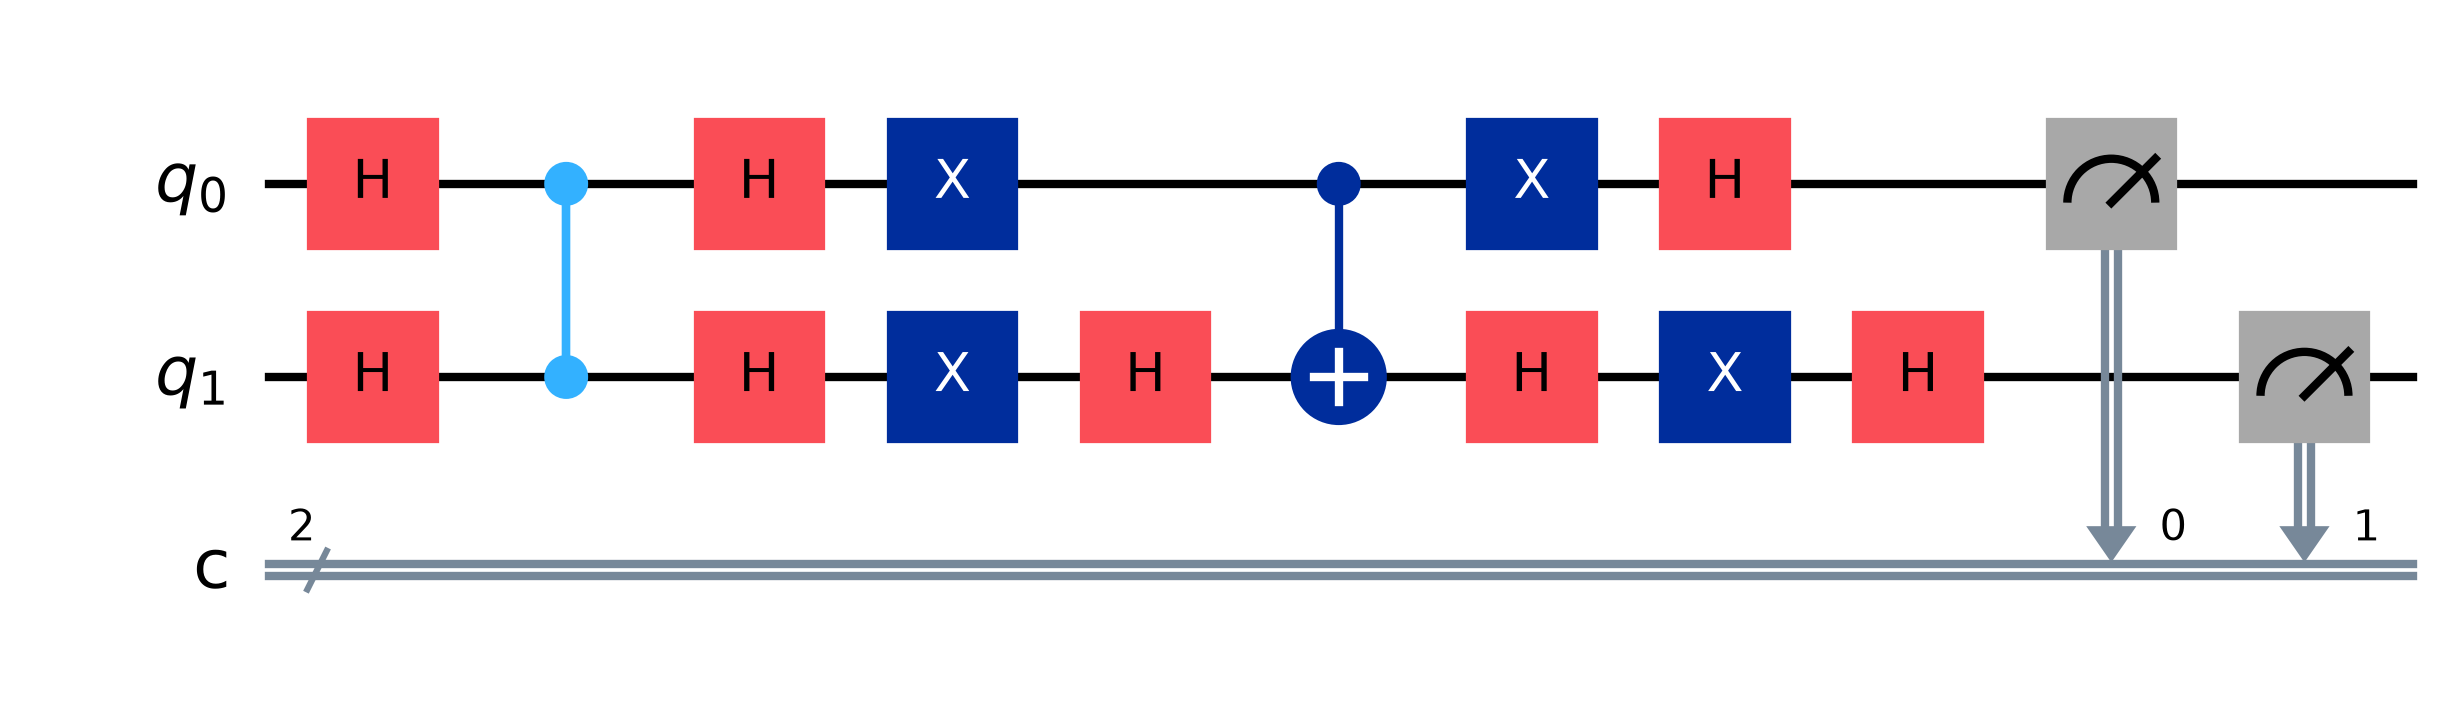

{'11': 1024}
Most probable state: 11
Success probability: 1.0


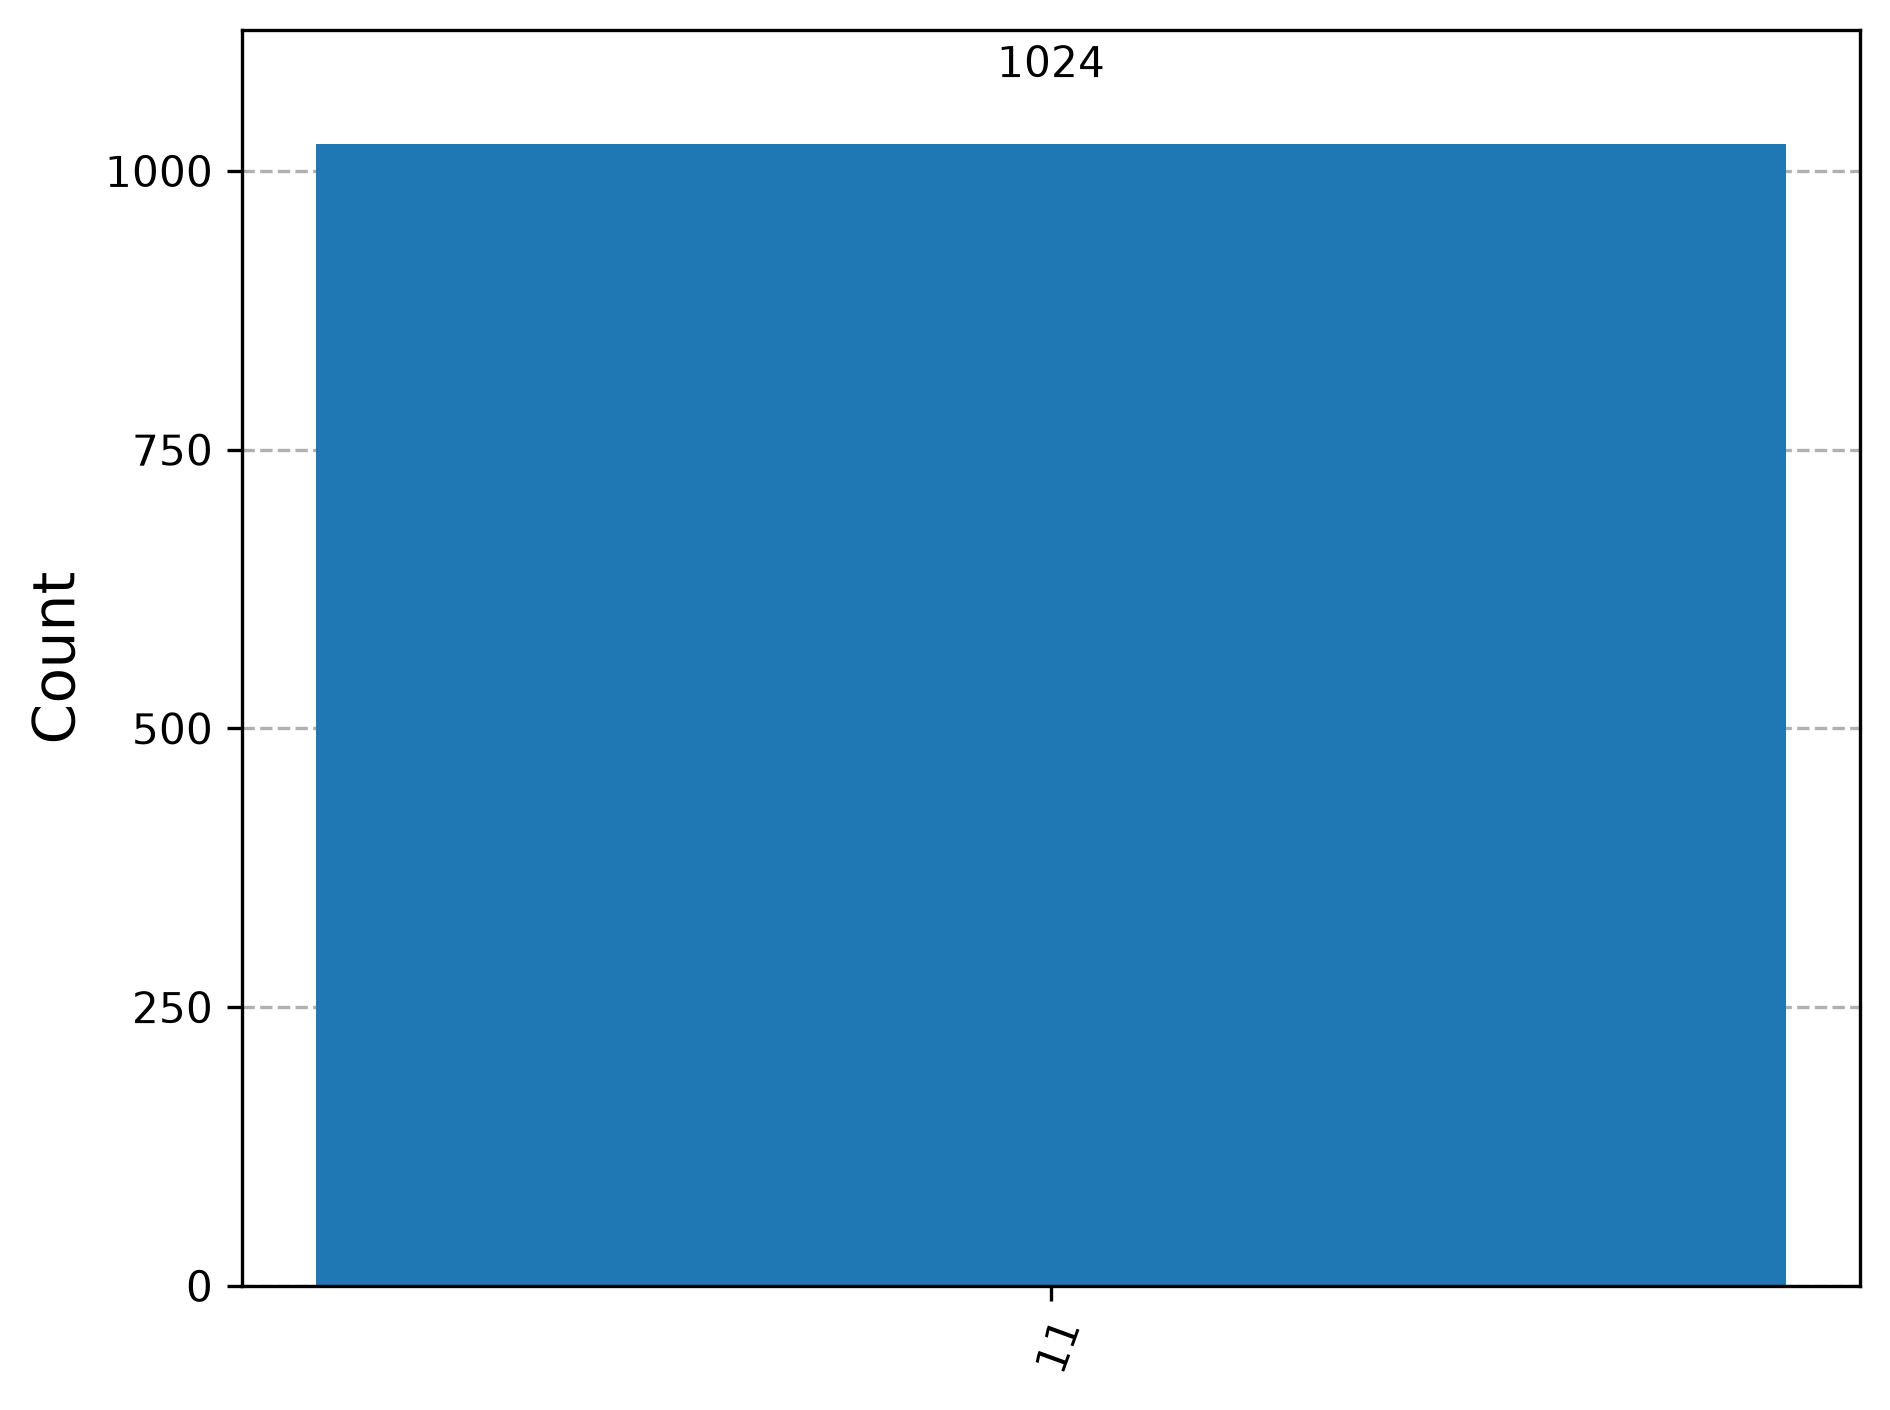

In [3]:
qc = QuantumCircuit(2, 2)

# Create uniform superposition
qc.h([0, 1])

# Oracle: mark |11>
qc.cz(0, 1)

# Diffusion operator
qc.h([0, 1])
qc.x([0, 1])
qc.h(1)
qc.cx(0, 1)
qc.h(1)
qc.x([0, 1])
qc.h([0, 1])

# Measurement
qc.measure([0, 1], [0, 1])

print(qc.draw())
display(qc.draw("mpl"))

result = backend.run(
    transpile(qc, backend), shots=1024
).result()
counts = result.get_counts()
print(counts)
print("Most probable state:", max(counts, key=counts.get))
print("Success probability:", counts.get("11", 0) / 1024)
display(plot_histogram(counts))

In [4]:
# Statevector verification after each stage
stage = QuantumCircuit(2)
stage.h([0, 1])
print("After Hadamard:", np.round(Statevector(stage).data, 3))
stage.cz(0, 1)
print("After oracle:  ", np.round(Statevector(stage).data, 3))
stage.h([0, 1]); stage.x([0, 1]); stage.h(1)
stage.cx(0, 1); stage.h(1); stage.x([0, 1]); stage.h([0, 1])
print("After diffusion:", np.round(Statevector(stage).data, 3))

After Hadamard: [0.5+0.j 0.5+0.j 0.5+0.j 0.5+0.j]
After oracle:   [ 0.5+0.j  0.5+0.j  0.5+0.j -0.5+0.j]
After diffusion: [ 0.+0.j  0.+0.j  0.+0.j -1.+0.j]


### Observation

The measurement gives **11 on all 1024 shots**, a success probability of 1. The statevector shows how: the Hadamards put equal amplitude 0.5 on every state, the oracle flips the sign of the $|11\rangle$ amplitude, and the diffusion operator reflects every amplitude about the mean, which drives the three unmarked amplitudes to 0 and the marked one to 1. For $N = 4$ and one marked state a **single Grover iteration is exact**.

## Task 2: Oracle Design for a Real-World Search Problem

### Problem Statement

Four records are represented by $00, 01, 10, 11$ and the record $|10\rangle$ satisfies the search condition. Design an oracle that marks only this state, run Grover search with it, and repeat the experiment for every target $|00\rangle, |01\rangle, |10\rangle, |11\rangle$. States are written in Qiskit order, with qubit 1 on the left.

### Program

In [5]:
oracle = QuantumCircuit(2)
# Mark |10>: flip qubit 0 so that CZ acts on the target
oracle.x(0)
oracle.cz(0, 1)
oracle.x(0)
print(oracle.draw())

     ┌───┐   ┌───┐
q_0: ┤ X ├─■─┤ X ├
     └───┘ │ └───┘
q_1: ──────■──────
                  


     ┌───┐┌───┐   ┌───┐┌───┐┌───┐     ┌───┐┌───┐     ┌─┐   
q_0: ┤ H ├┤ X ├─■─┤ X ├┤ H ├┤ X ├──■──┤ X ├┤ H ├─────┤M├───
     ├───┤└───┘ │ ├───┤├───┤├───┤┌─┴─┐├───┤├───┤┌───┐└╥┘┌─┐
q_1: ┤ H ├──────■─┤ H ├┤ X ├┤ H ├┤ X ├┤ H ├┤ X ├┤ H ├─╫─┤M├
     └───┘        └───┘└───┘└───┘└───┘└───┘└───┘└───┘ ║ └╥┘
c: 2/═════════════════════════════════════════════════╩══╩═
                                                      0  1 


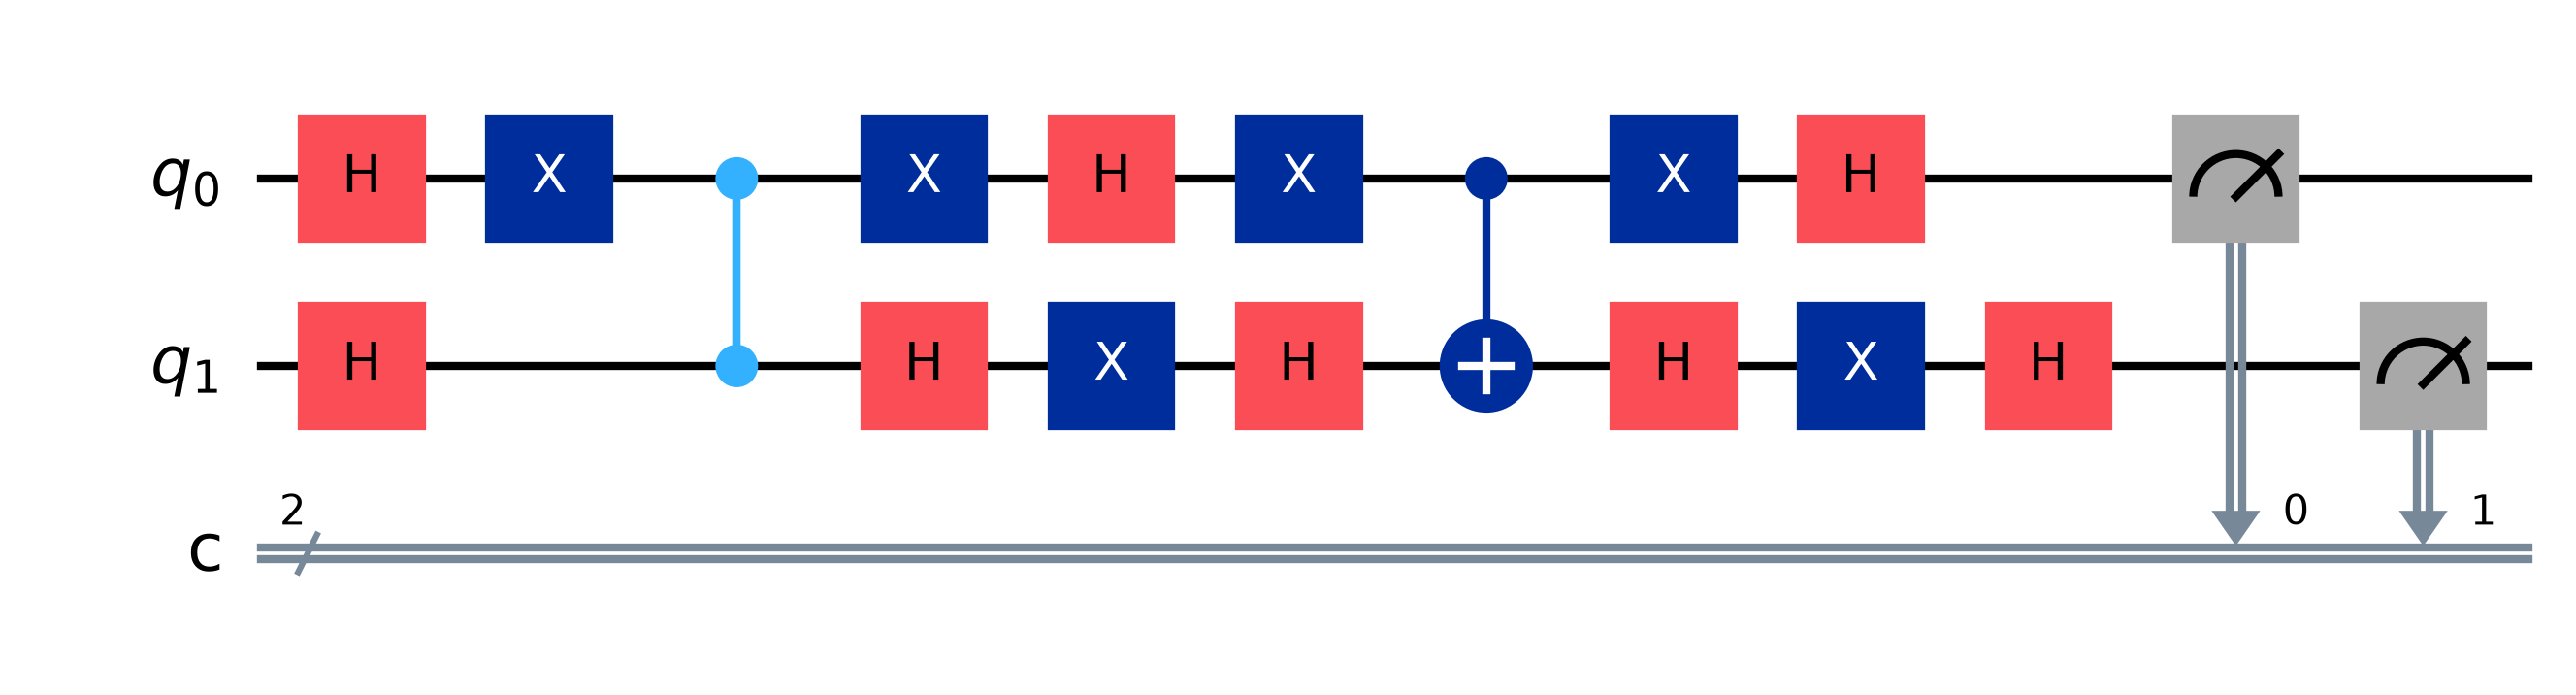

target  most probable  correct?


    00             00  True


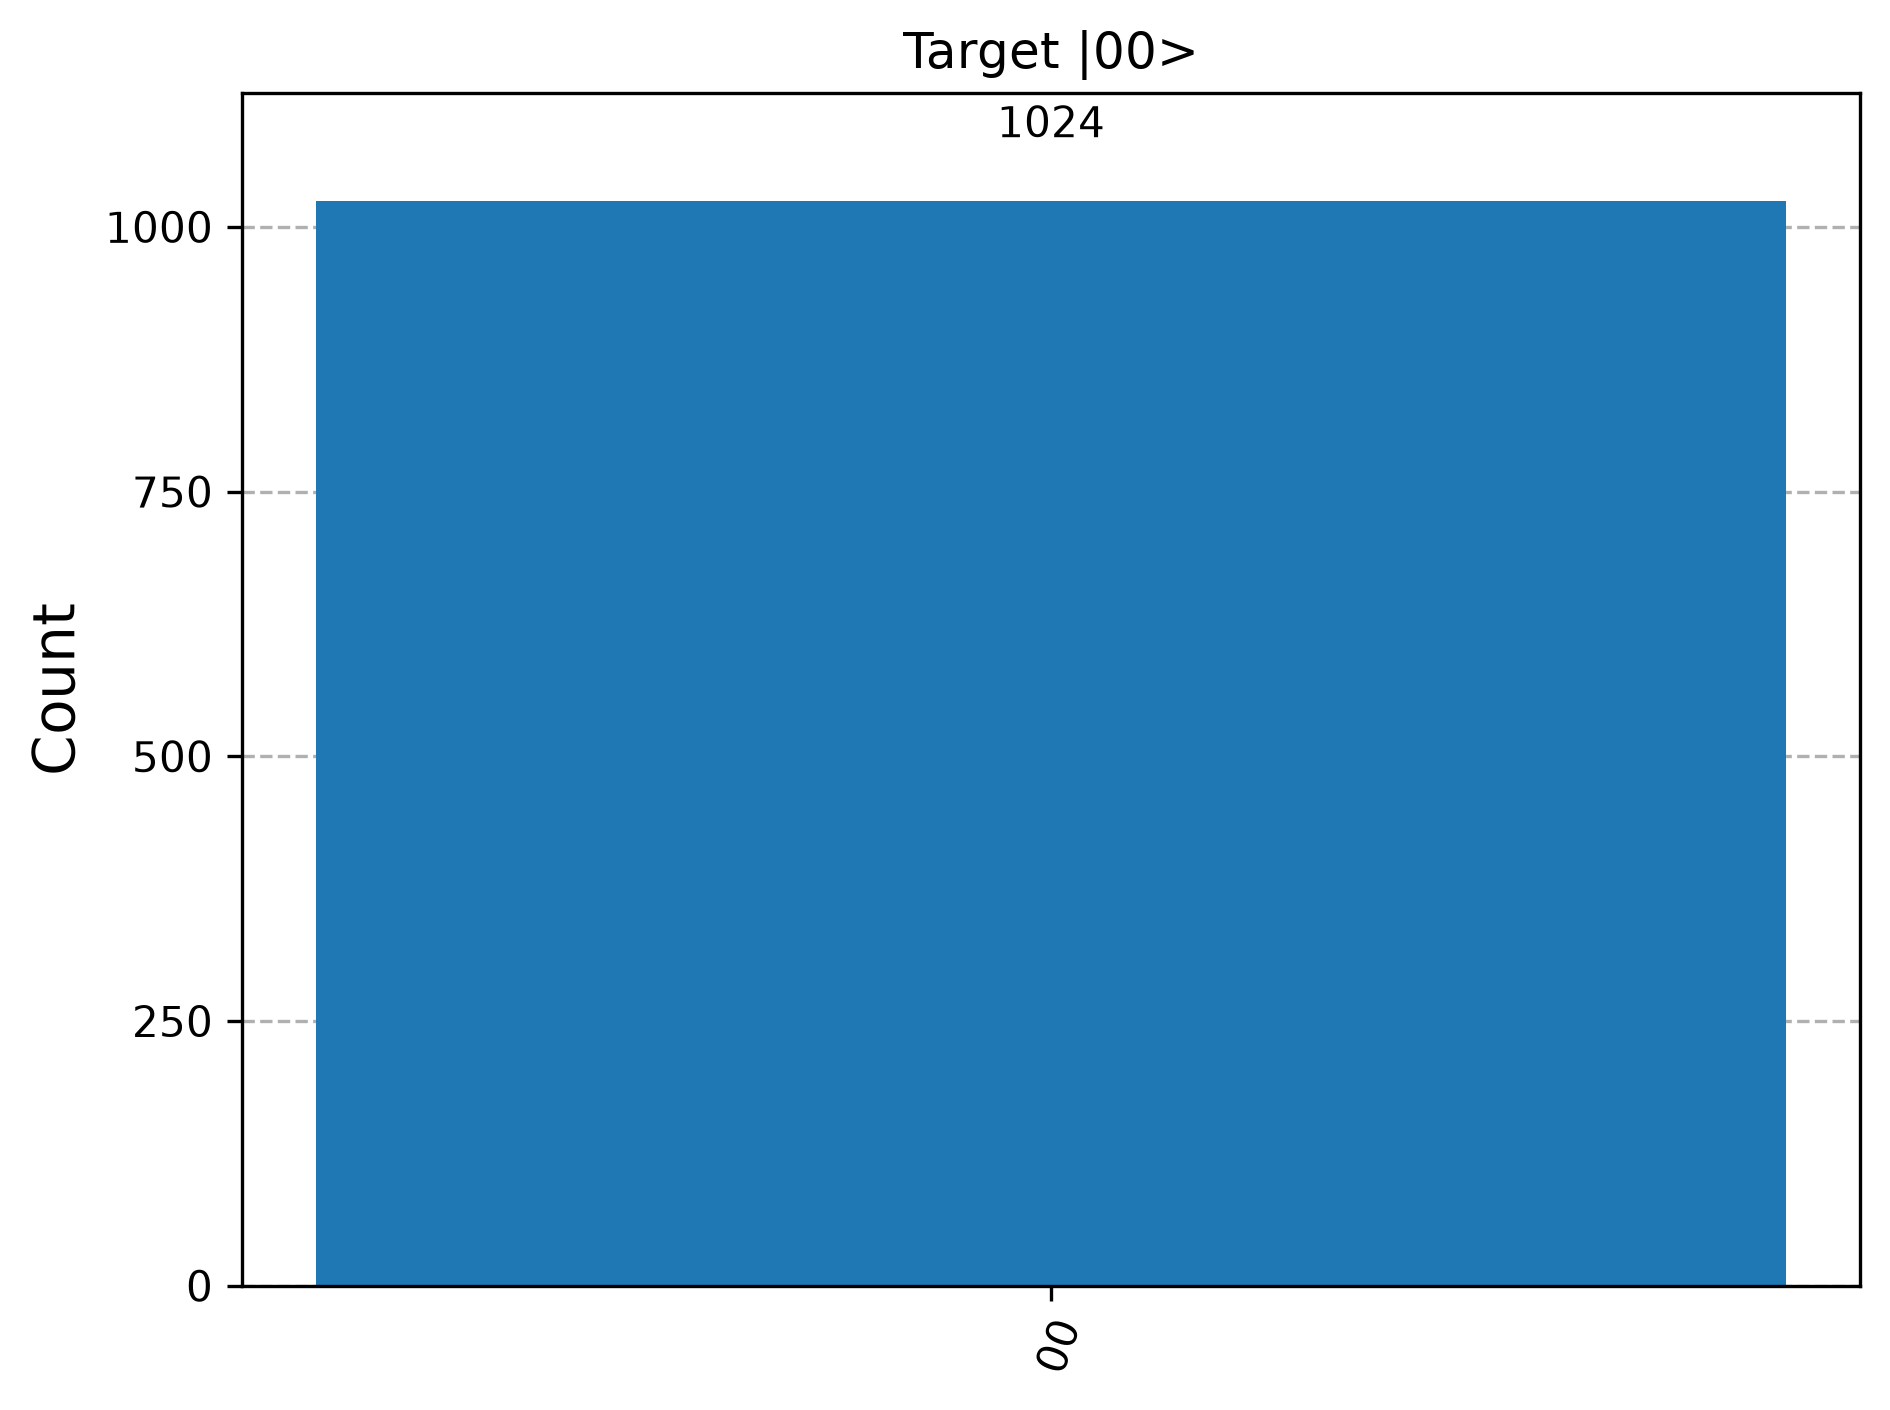

    01             01  True


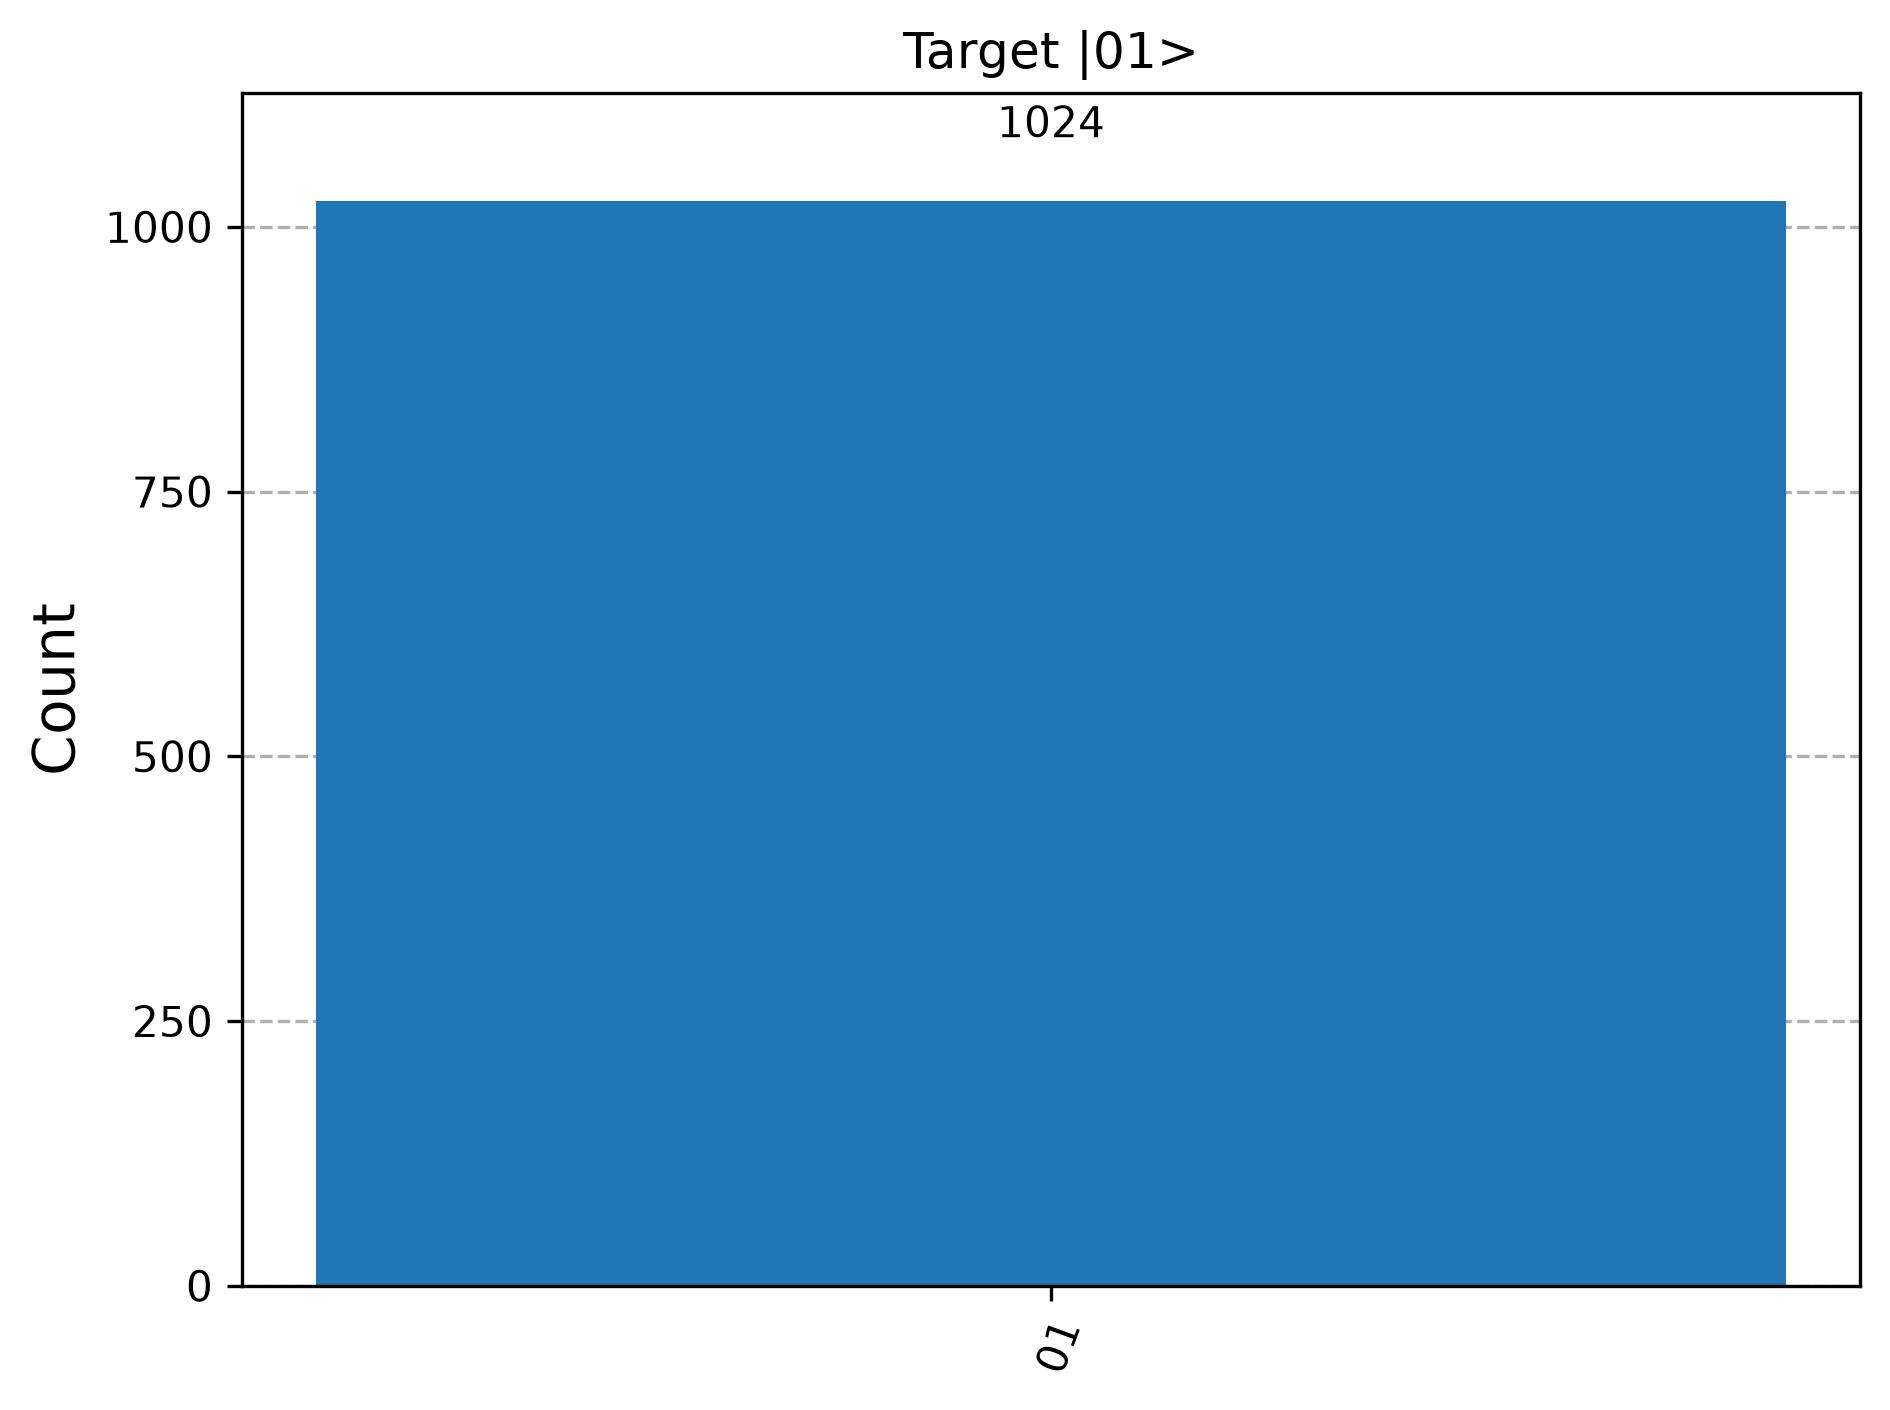

    10             10  True


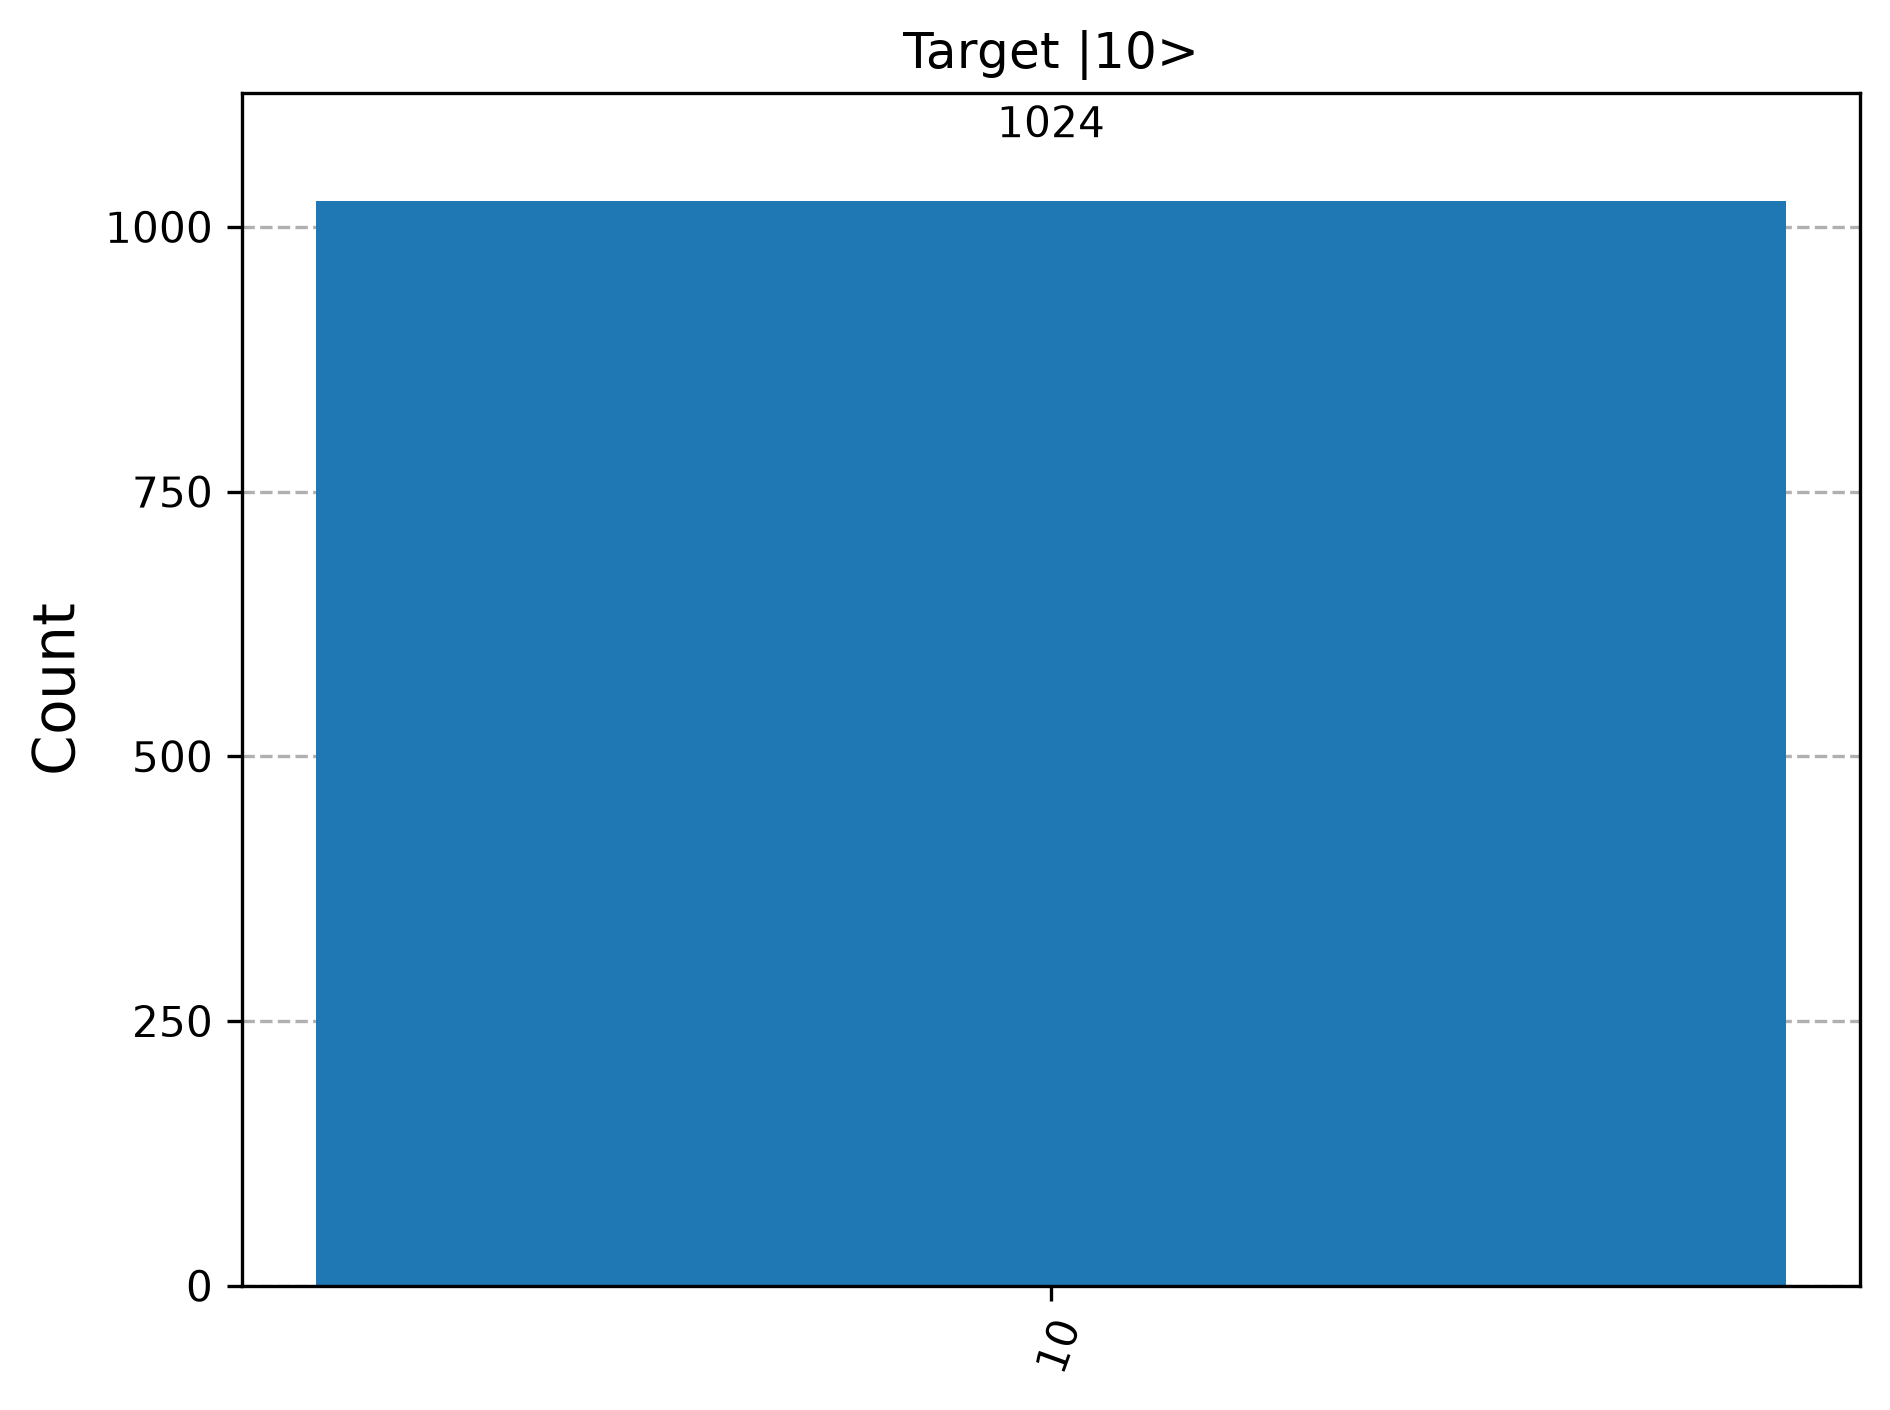

    11             11  True


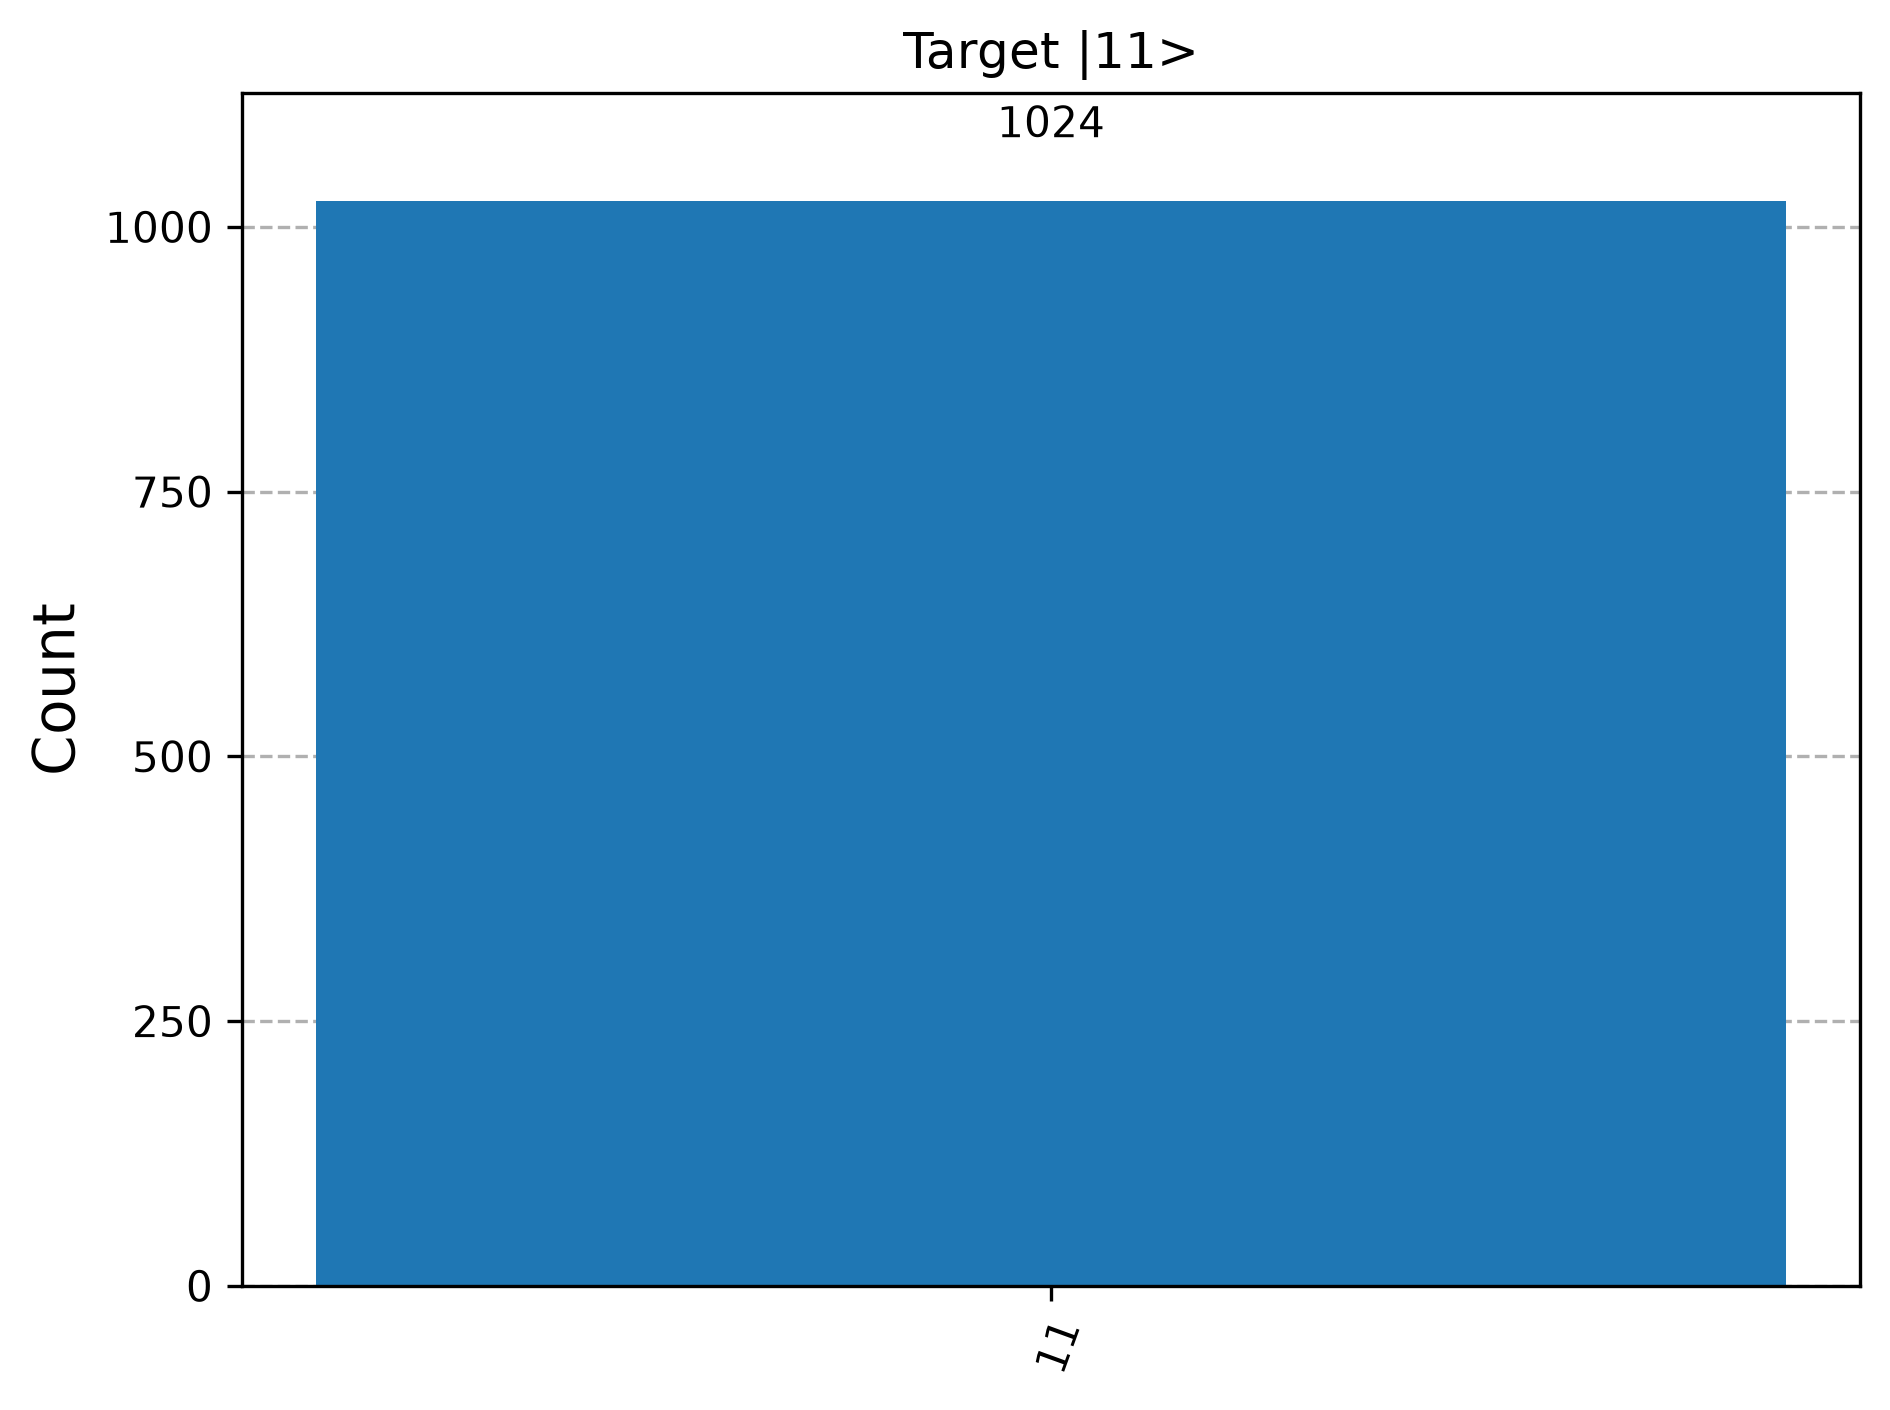

In [6]:
def grover_2q(target):
    qc = QuantumCircuit(2, 2)
    # Superposition
    qc.h([0, 1])
    # Oracle: X on the qubits that are 0 in the target, then CZ
    zeros = [i for i, bit in enumerate(reversed(target)) if bit == "0"]
    if zeros:
        qc.x(zeros)
    qc.cz(0, 1)
    if zeros:
        qc.x(zeros)
    # Diffusion
    qc.h([0, 1])
    qc.x([0, 1])
    qc.h(1)
    qc.cx(0, 1)
    qc.h(1)
    qc.x([0, 1])
    qc.h([0, 1])
    qc.measure([0, 1], [0, 1])
    return qc

qc = grover_2q("10")
print(qc.draw())
display(qc.draw("mpl"))

print("target  most probable  correct?")
for target in ["00", "01", "10", "11"]:
    counts = backend.run(
        transpile(grover_2q(target), backend), shots=1024
    ).result().get_counts()
    best = max(counts, key=counts.get)
    print(f"{target:>6}  {best:>13}  {best == target}")
    display(plot_histogram(counts, title=f"Target |{target}>"))

### Observation

| Target | Most probable state | Correct? |
| --- | --- | --- |
| $|00\rangle$ | 00 | Yes |
| $|01\rangle$ | 01 | Yes |
| $|10\rangle$ | 10 | Yes |
| $|11\rangle$ | 11 | Yes |
*Grover search for each target record*

Each target was found with **probability 1** after one iteration. **Only the oracle changed between the four runs**: X gates surround the CZ so that it flips the phase of the wanted record, while the diffusion operator stayed identical. The oracle carries the problem-specific information and the rest of Grover's circuit is generic.

## Task 3: Optimal Number of Grover Iterations

### Problem Statement

The probability of finding the target does not increase indefinitely with repeated Grover iterations. For $N = 4, 8, 16$ (2, 3 and 4 qubits) apply the Grover iteration different numbers of times, measure the target probability, compare the experimental best with the estimate $\lfloor \frac{\pi}{4}\sqrt{N/M} \rfloor$, and explain why more iterations eventually reduce the probability.

### Program

In [7]:
# Basic iteration estimate
N = 16
M = 1
iterations = int(np.floor((np.pi / 4) * np.sqrt(N / M)))
print("Recommended iterations:", iterations)

Recommended iterations: 3


n = 2, N = 4: recommended 1, experimental best 1
   P(target) per iteration: [0.262, 1.0, 0.231, 0.251, 1.0, 0.231, 0.252]


n = 3, N = 8: recommended 2, experimental best 2
   P(target) per iteration: [0.136, 0.765, 0.946, 0.324, 0.011, 0.538, 1.0]


n = 4, N = 16: recommended 3, experimental best 3
   P(target) per iteration: [0.065, 0.456, 0.912, 0.955, 0.603, 0.132, 0.021]


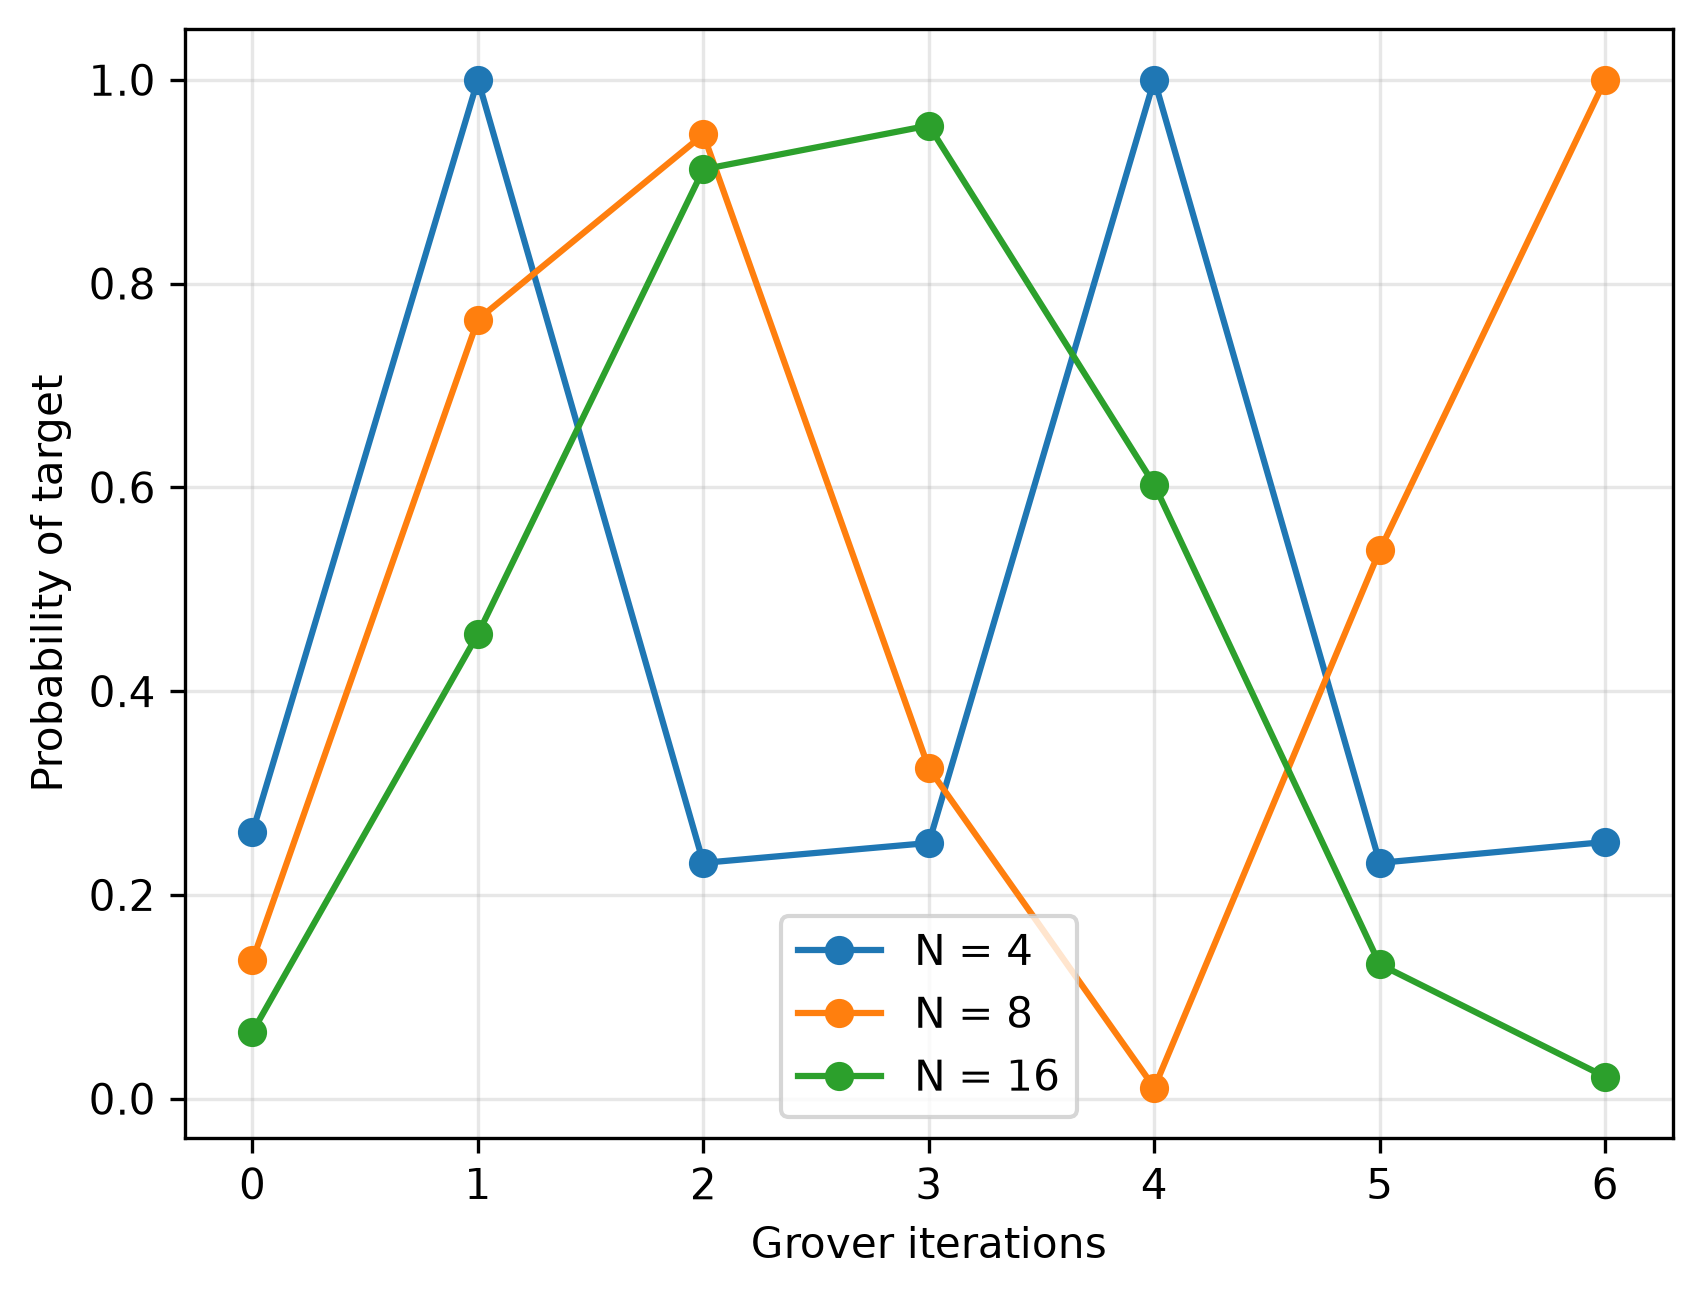

In [8]:
# n-qubit Grover circuit with a list of marked states
def phase_flip(qc, n, target):
    zeros = [i for i, bit in enumerate(reversed(target)) if bit == "0"]
    if zeros:
        qc.x(zeros)
    qc.h(n - 1)
    qc.mcx(list(range(n - 1)), n - 1)
    qc.h(n - 1)
    if zeros:
        qc.x(zeros)

def grover(n, targets, iterations):
    qc = QuantumCircuit(n, n)
    qc.h(range(n))
    for _ in range(iterations):
        # Oracle
        for target in targets:
            phase_flip(qc, n, target)
        # Diffusion
        qc.h(range(n))
        phase_flip(qc, n, "0" * n)
        qc.h(range(n))
    qc.measure(range(n), range(n))
    return qc

def success(n, targets, iterations, shots=1024):
    counts = backend.run(
        transpile(grover(n, targets, iterations), backend),
        shots=shots
    ).result().get_counts()
    return sum(counts.get(t, 0) for t in targets) / shots

results = {}
for n in [2, 3, 4]:
    target = "1" * n
    probs = [success(n, [target], k) for k in range(7)]
    results[n] = probs
    # first peak: the iteration after which the probability drops
    best = next(k for k in range(6) if probs[k] >= probs[k + 1])
    rec = int(np.floor((np.pi / 4) * np.sqrt(2**n)))
    print(f"n = {n}, N = {2**n}: recommended {rec}, experimental best {best}")
    print("   P(target) per iteration:", [round(p, 3) for p in probs])

for n, probs in results.items():
    plt.plot(range(7), probs, marker="o", label=f"N = {2**n}")
plt.xlabel("Grover iterations")
plt.ylabel("Probability of target")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Observation

| Qubits | Search space N | Recommended iterations | Experimental best |
| --- | --- | --- | --- |
| 2 | 4 | 1 | 1 |
| 3 | 8 | 2 | 2 |
| 4 | 16 | 3 | 3 |
*Optimal number of Grover iterations*

The first experimental peak agreed with the estimate $\lfloor \frac{\pi}{4}\sqrt{N} \rfloor$ in all three cases, and the plot shows the probability **rising, peaking and then falling again**, with a second peak appearing later because the rotation is periodic. Each iteration rotates the state by a fixed angle $2\theta$ with $\sin\theta = \sqrt{M/N}$ in the plane spanned by the marked and unmarked states. The probability is $\sin^2((2k+1)\theta)$, so **after the peak the rotation overshoots the target** and the amplitude moves back toward the unmarked states. More iterations do not mean a better search; the count must be chosen from $N$ and $M$.

## Task 4: Multiple Target States

### Problem Statement

Modify Grover's algorithm so that more than one state is marked. In the four-state space mark $|01\rangle$ and $|10\rangle$, construct the oracle, record the histogram and the probability of each marked state, compare $M = 1$ with $M = 2$ and investigate how the required number of iterations changes.

### Program

     ┌───┐        ┌───┐   ┌───┐┌───┐┌───┐     ┌───┐┌───┐     ┌─┐   
q_0: ┤ H ├──────■─┤ X ├─■─┤ X ├┤ H ├┤ X ├──■──┤ X ├┤ H ├─────┤M├───
     ├───┤┌───┐ │ ├───┤ │ ├───┤├───┤├───┤┌─┴─┐├───┤├───┤┌───┐└╥┘┌─┐
q_1: ┤ H ├┤ X ├─■─┤ X ├─■─┤ H ├┤ X ├┤ H ├┤ X ├┤ H ├┤ X ├┤ H ├─╫─┤M├
     └───┘└───┘   └───┘   └───┘└───┘└───┘└───┘└───┘└───┘└───┘ ║ └╥┘
c: 2/═════════════════════════════════════════════════════════╩══╩═
                                                              0  1 


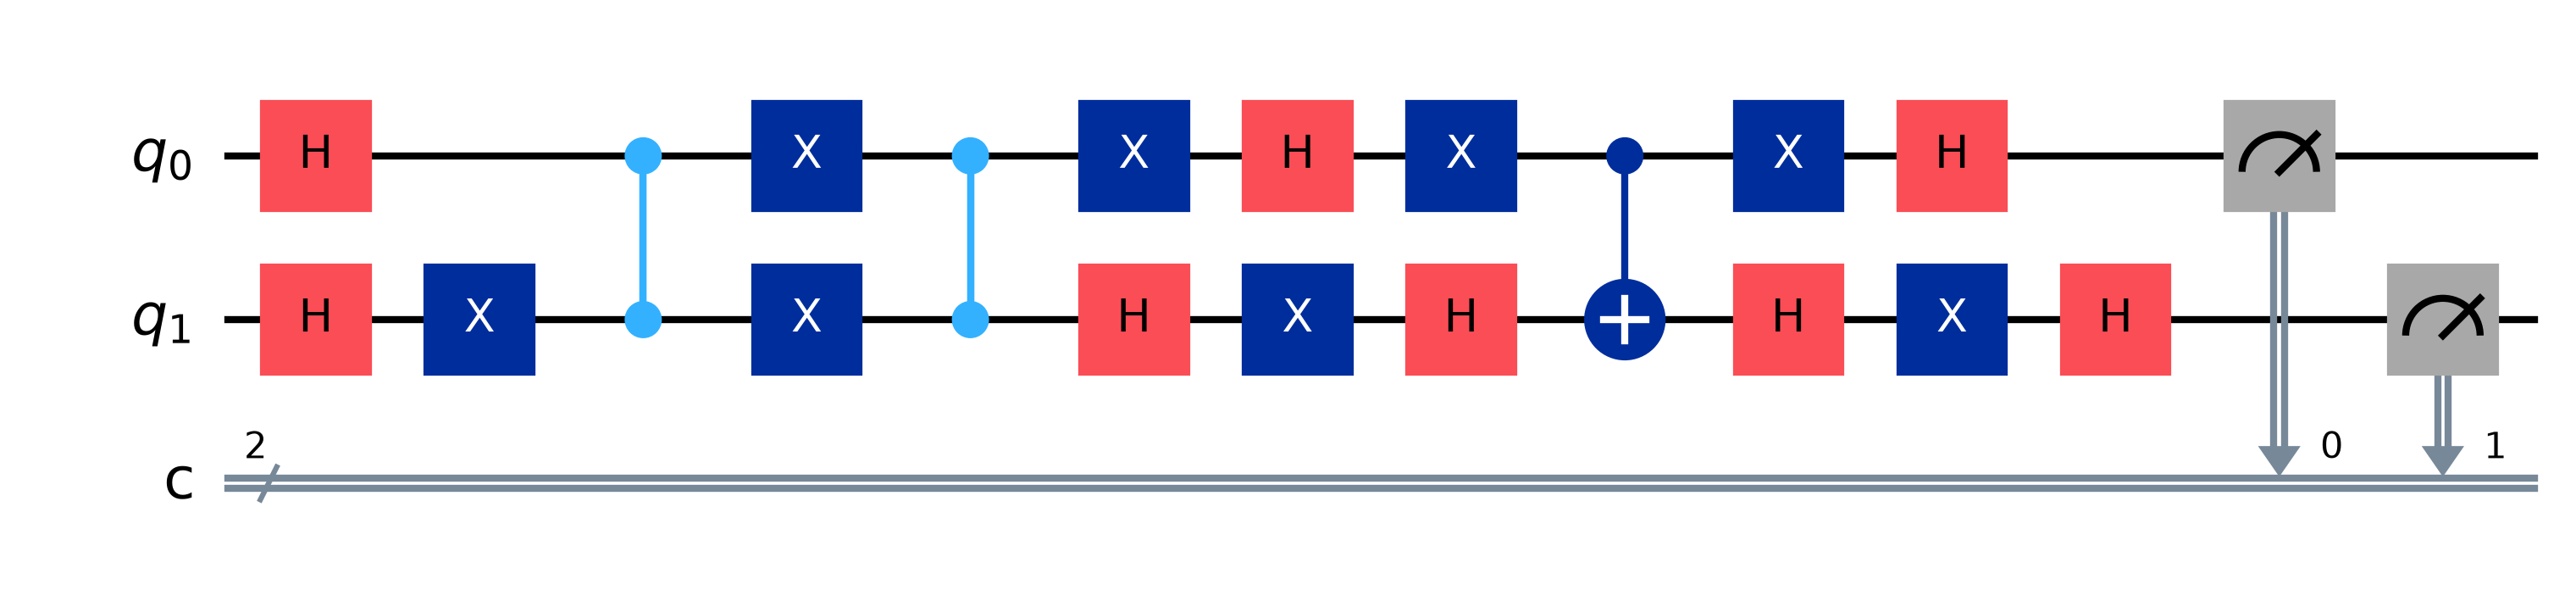

{'10': 282, '01': 243, '00': 249, '11': 250}
P(01) = 0.237
P(10) = 0.275


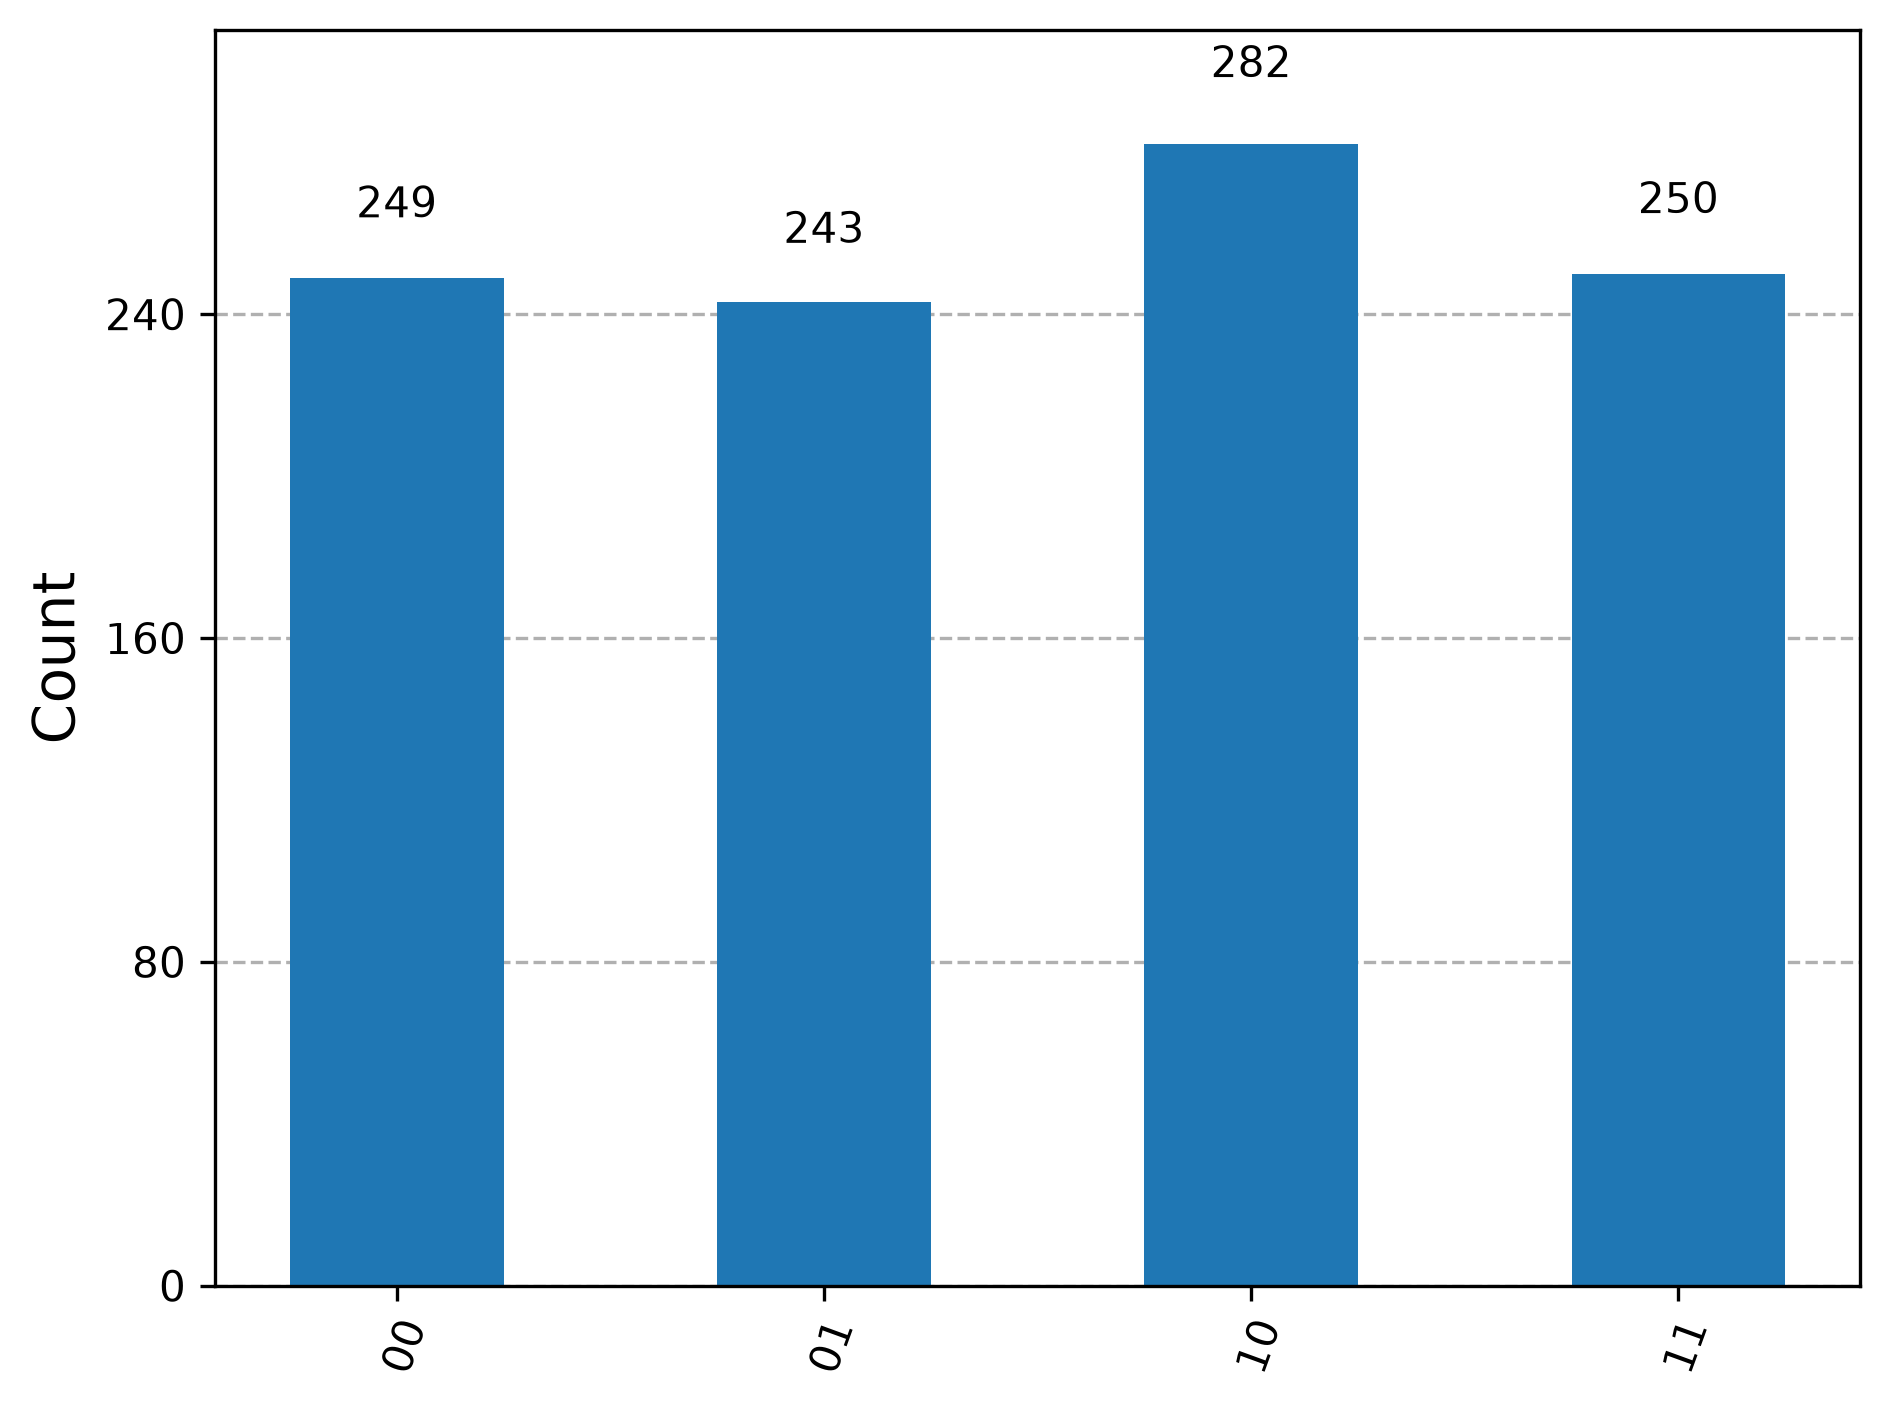

In [9]:
qc = QuantumCircuit(2, 2)

# Superposition
qc.h([0, 1])

# Mark |01>
qc.x(1)
qc.cz(0, 1)
qc.x(1)

# Mark |10>
qc.x(0)
qc.cz(0, 1)
qc.x(0)

# Diffusion
qc.h([0, 1])
qc.x([0, 1])
qc.h(1)
qc.cx(0, 1)
qc.h(1)
qc.x([0, 1])
qc.h([0, 1])

qc.measure([0, 1], [0, 1])
print(qc.draw())
display(qc.draw("mpl"))

counts = backend.run(
    transpile(qc, backend), shots=1024
).result().get_counts()
print(counts)
for state in ["01", "10"]:
    print(f"P({state}) =", round(counts.get(state, 0) / 1024, 3))
display(plot_histogram(counts))

In [10]:
# Iterations needed for M = 1 and M = 2 in N = 4 and N = 8
for n in [2, 3]:
    N = 2**n
    for targets in [["1" * n], ["0" + "1" * (n - 1), "1" + "0" * (n - 1)]]:
        M = len(targets)
        rec = int(np.floor((np.pi / 4) * np.sqrt(N / M)))
        probs = [round(success(n, targets, k), 3) for k in range(4)]
        print(f"N = {N}, M = {M}: recommended {rec} iteration(s),",
              "P(marked) for k = 0..3:", probs)

N = 4, M = 1: recommended 1 iteration(s), P(marked) for k = 0..3: [0.253, 1.0, 0.243, 0.252]


N = 4, M = 2: recommended 1 iteration(s), P(marked) for k = 0..3: [0.497, 0.517, 0.483, 0.503]


N = 8, M = 1: recommended 2 iteration(s), P(marked) for k = 0..3: [0.119, 0.797, 0.951, 0.317]


N = 8, M = 2: recommended 1 iteration(s), P(marked) for k = 0..3: [0.265, 1.0, 0.251, 0.272]


### Observation

With two marked states in $N = 4$ the histogram after one iteration is **flat: every state has probability close to 0.25**, so each marked state keeps 0.25 and the search gains nothing. This is the special case $M = N/2$, where $\theta = \pi/4$ and one iteration rotates the state straight through the marked subspace and out again; the recommended count $\lfloor \frac{\pi}{4}\sqrt{2} \rfloor = 1$ is simply not useful here.

In $N = 8$ the effect of $M$ is visible: one marked state needs **2 iterations** (probability about 0.95), while two marked states reach **probability 1 after a single iteration**. **More marked states need fewer iterations** because the rotation angle per iteration, $2\theta$ with $\sin\theta = \sqrt{M/N}$, grows with $M$, so the state reaches the marked subspace sooner.

## Task 5: Noise, Search Accuracy and Scalability

### Problem Statement

Investigate how noise influences Grover search as the number of qubits grows. For $n = 2, 3, 4, 5$ run the optimal-iteration circuit on an ideal simulator and on a noisy simulator (depolarizing error of 1 percent on single-qubit gates and 3 percent on CX), and record qubits, $N$, depth, gate count and success probability. Explain why a theoretically faster search becomes difficult on noisy hardware.

### Program

n   N  iters  depth  gates  ideal P  noisy P


2   4      1      8     12     1.000    0.910


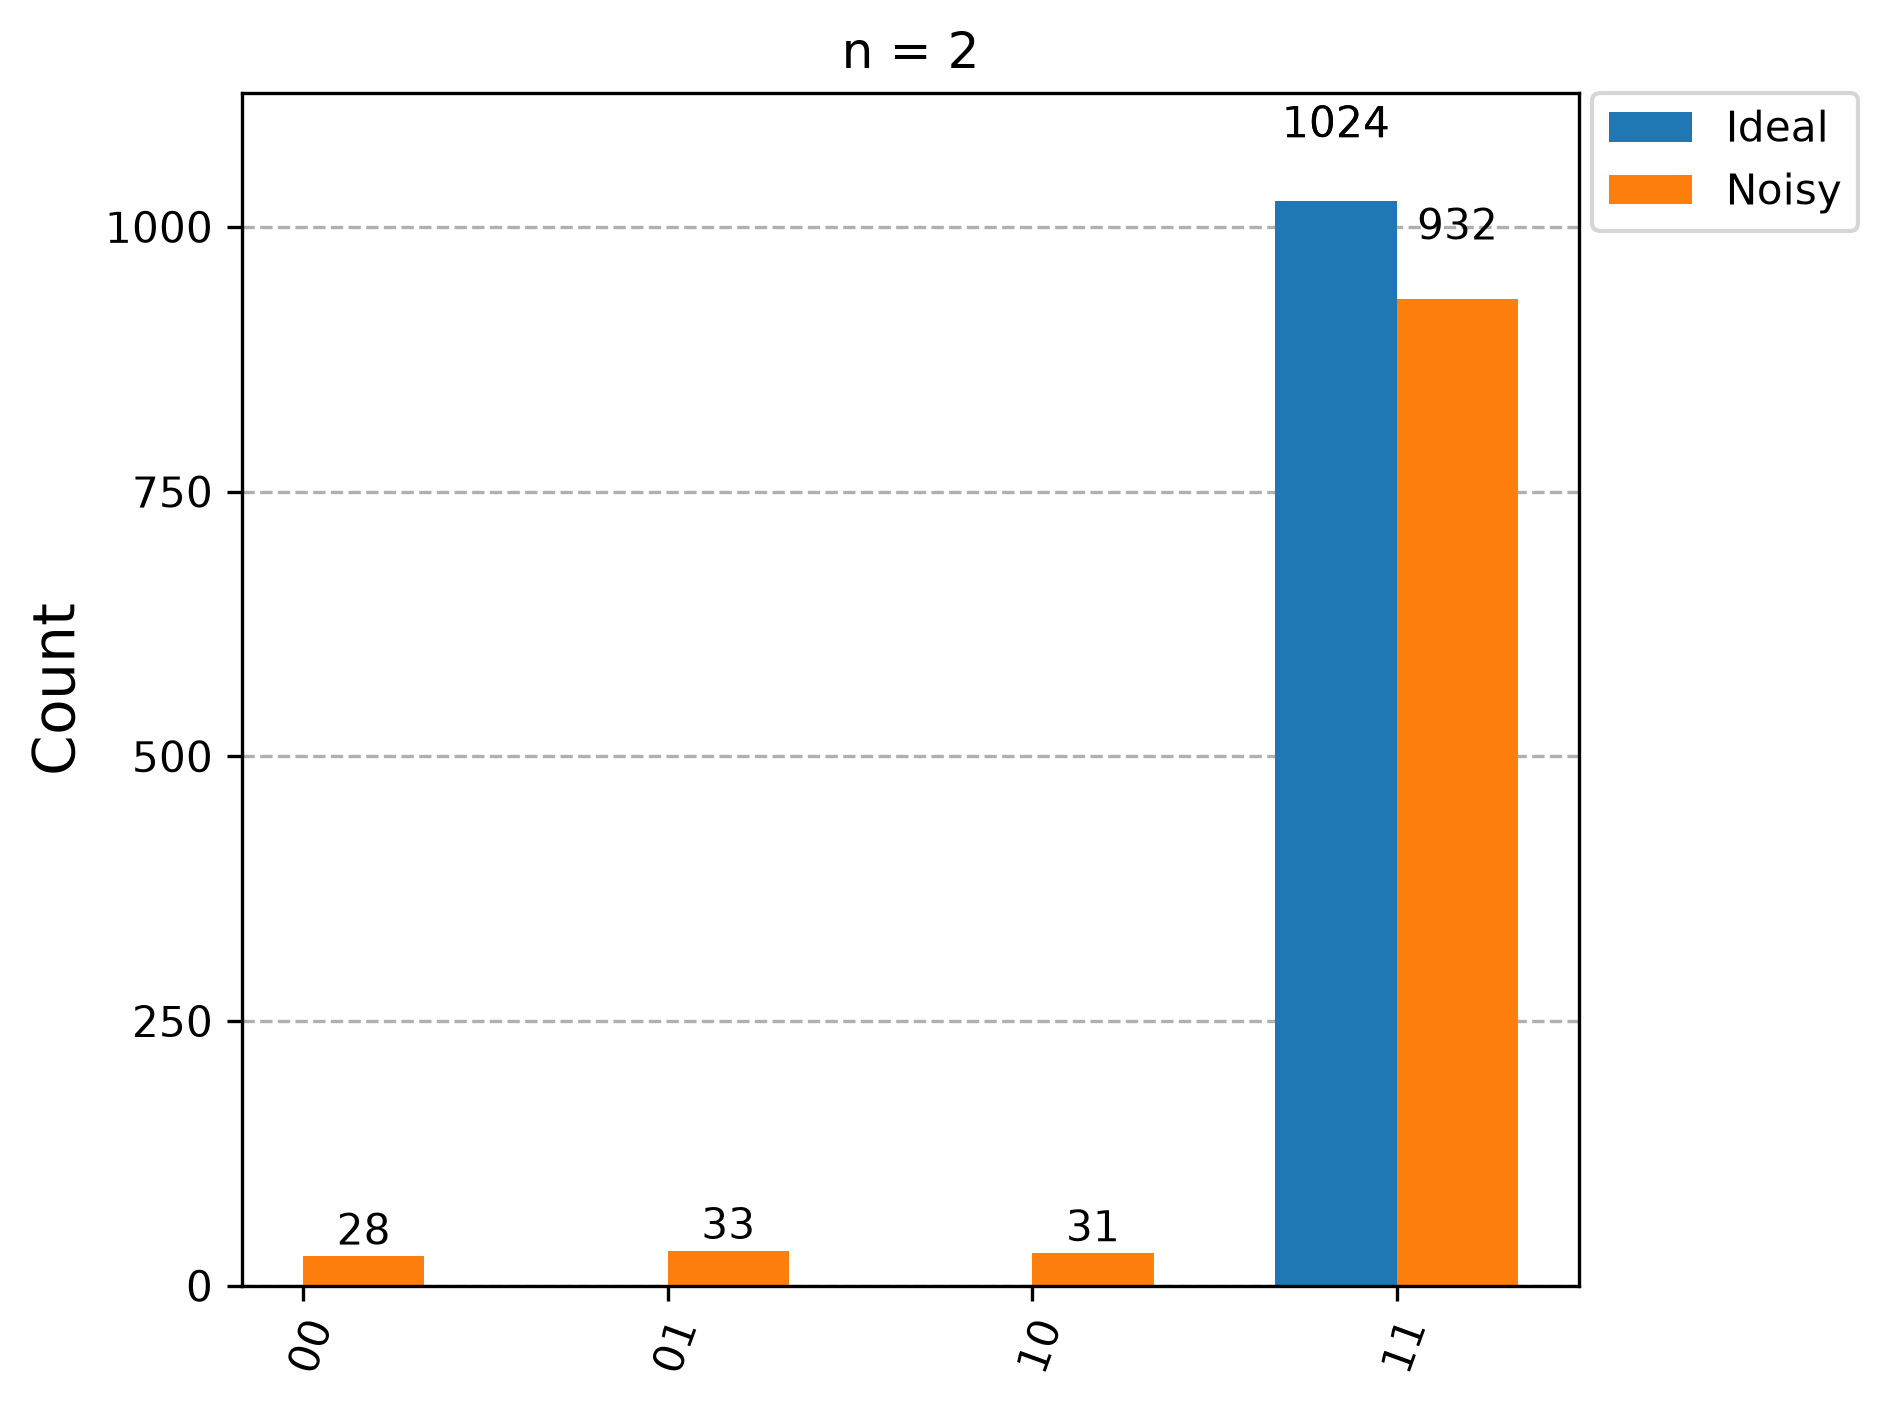

3   8      2     50     82     0.951    0.505


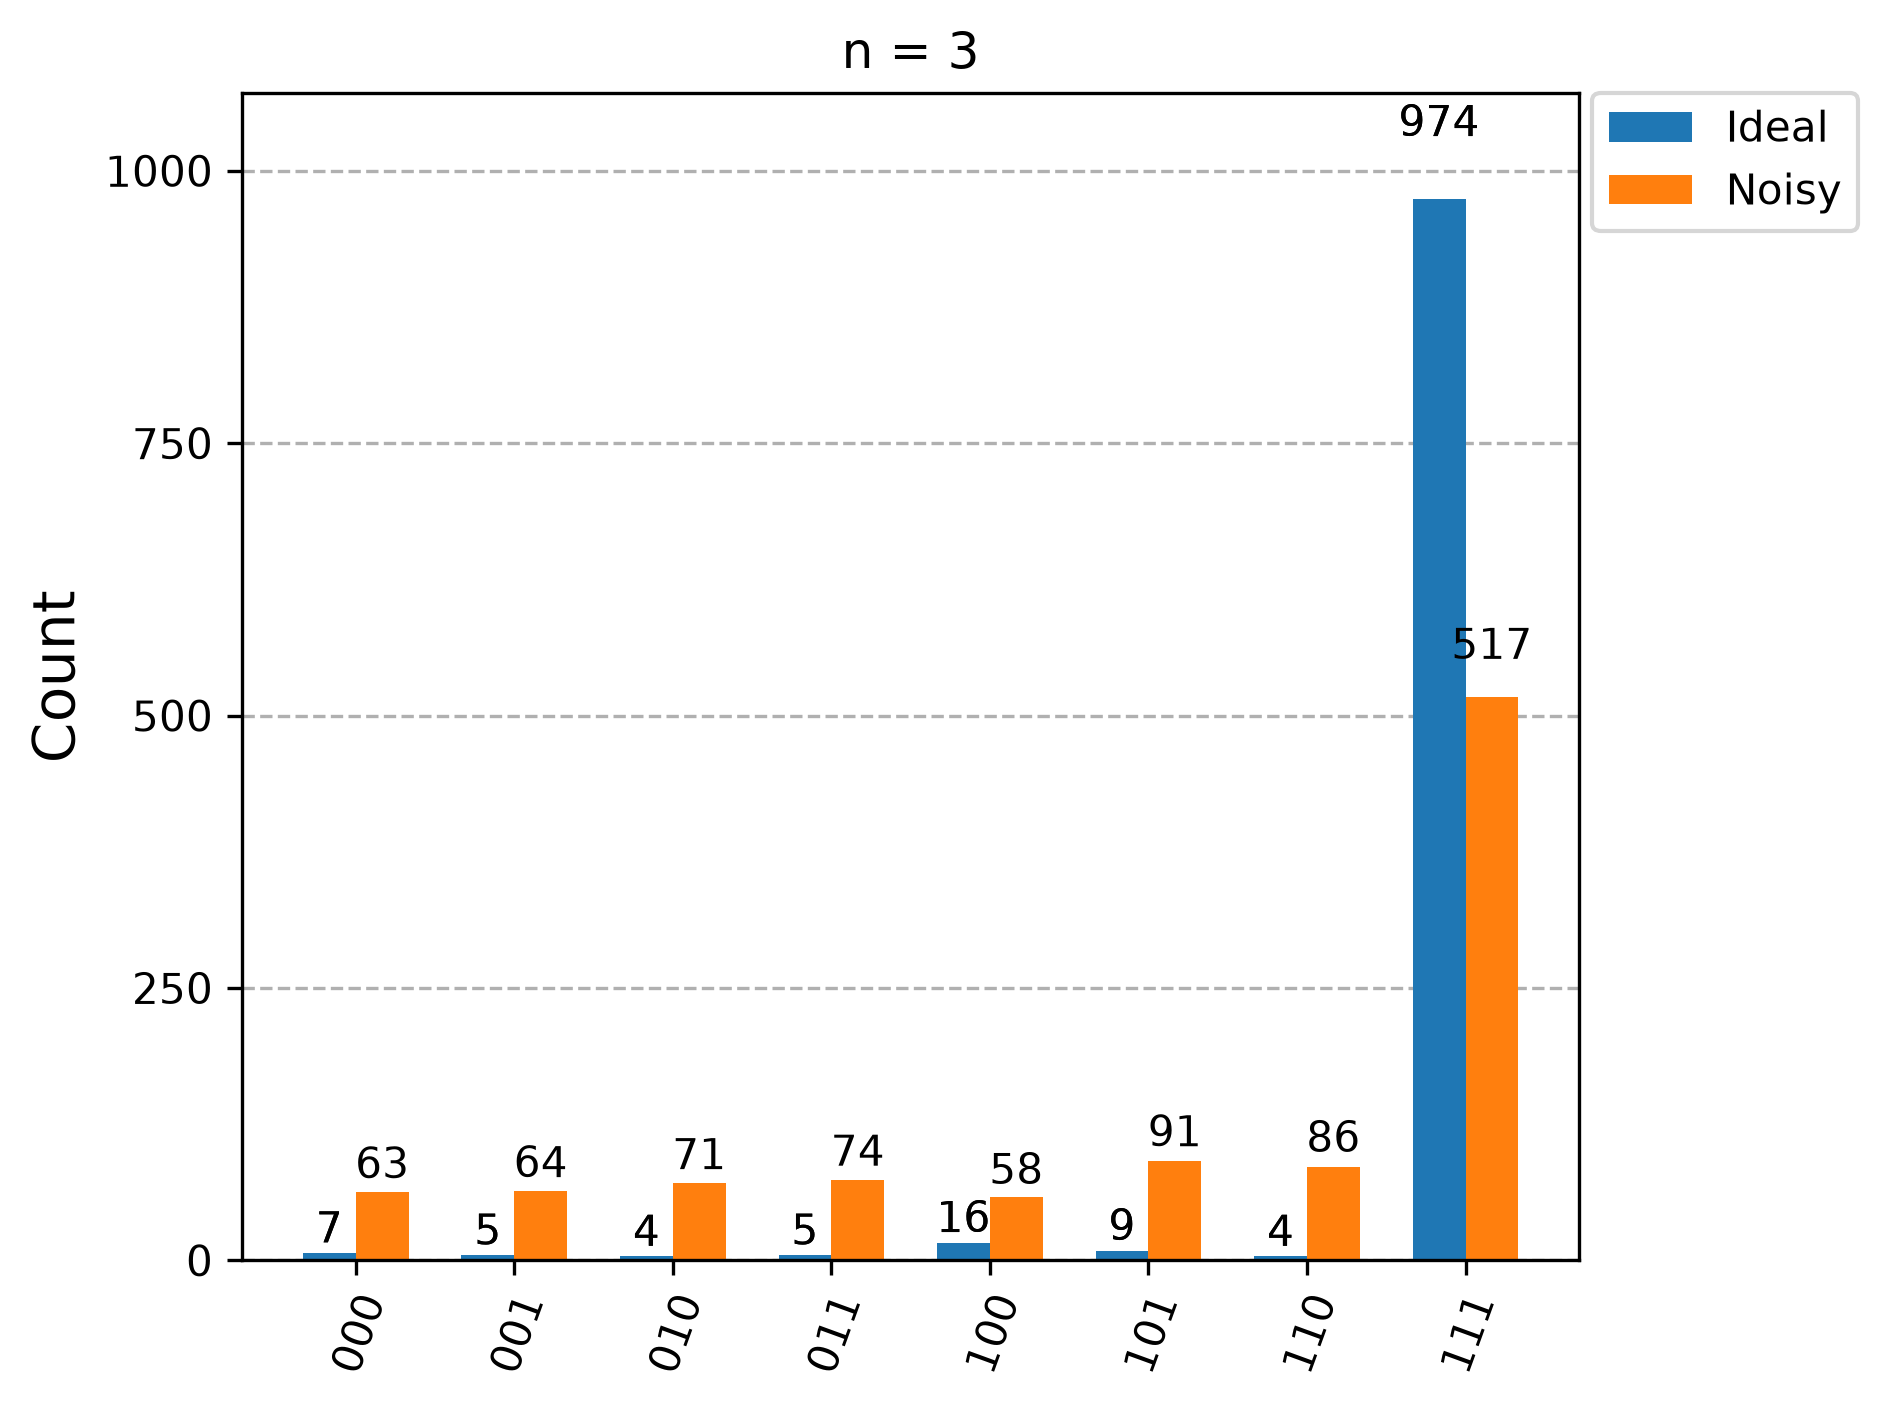

4  16      3    170    230     0.960    0.135


5  32      4    603    759     0.997    0.032


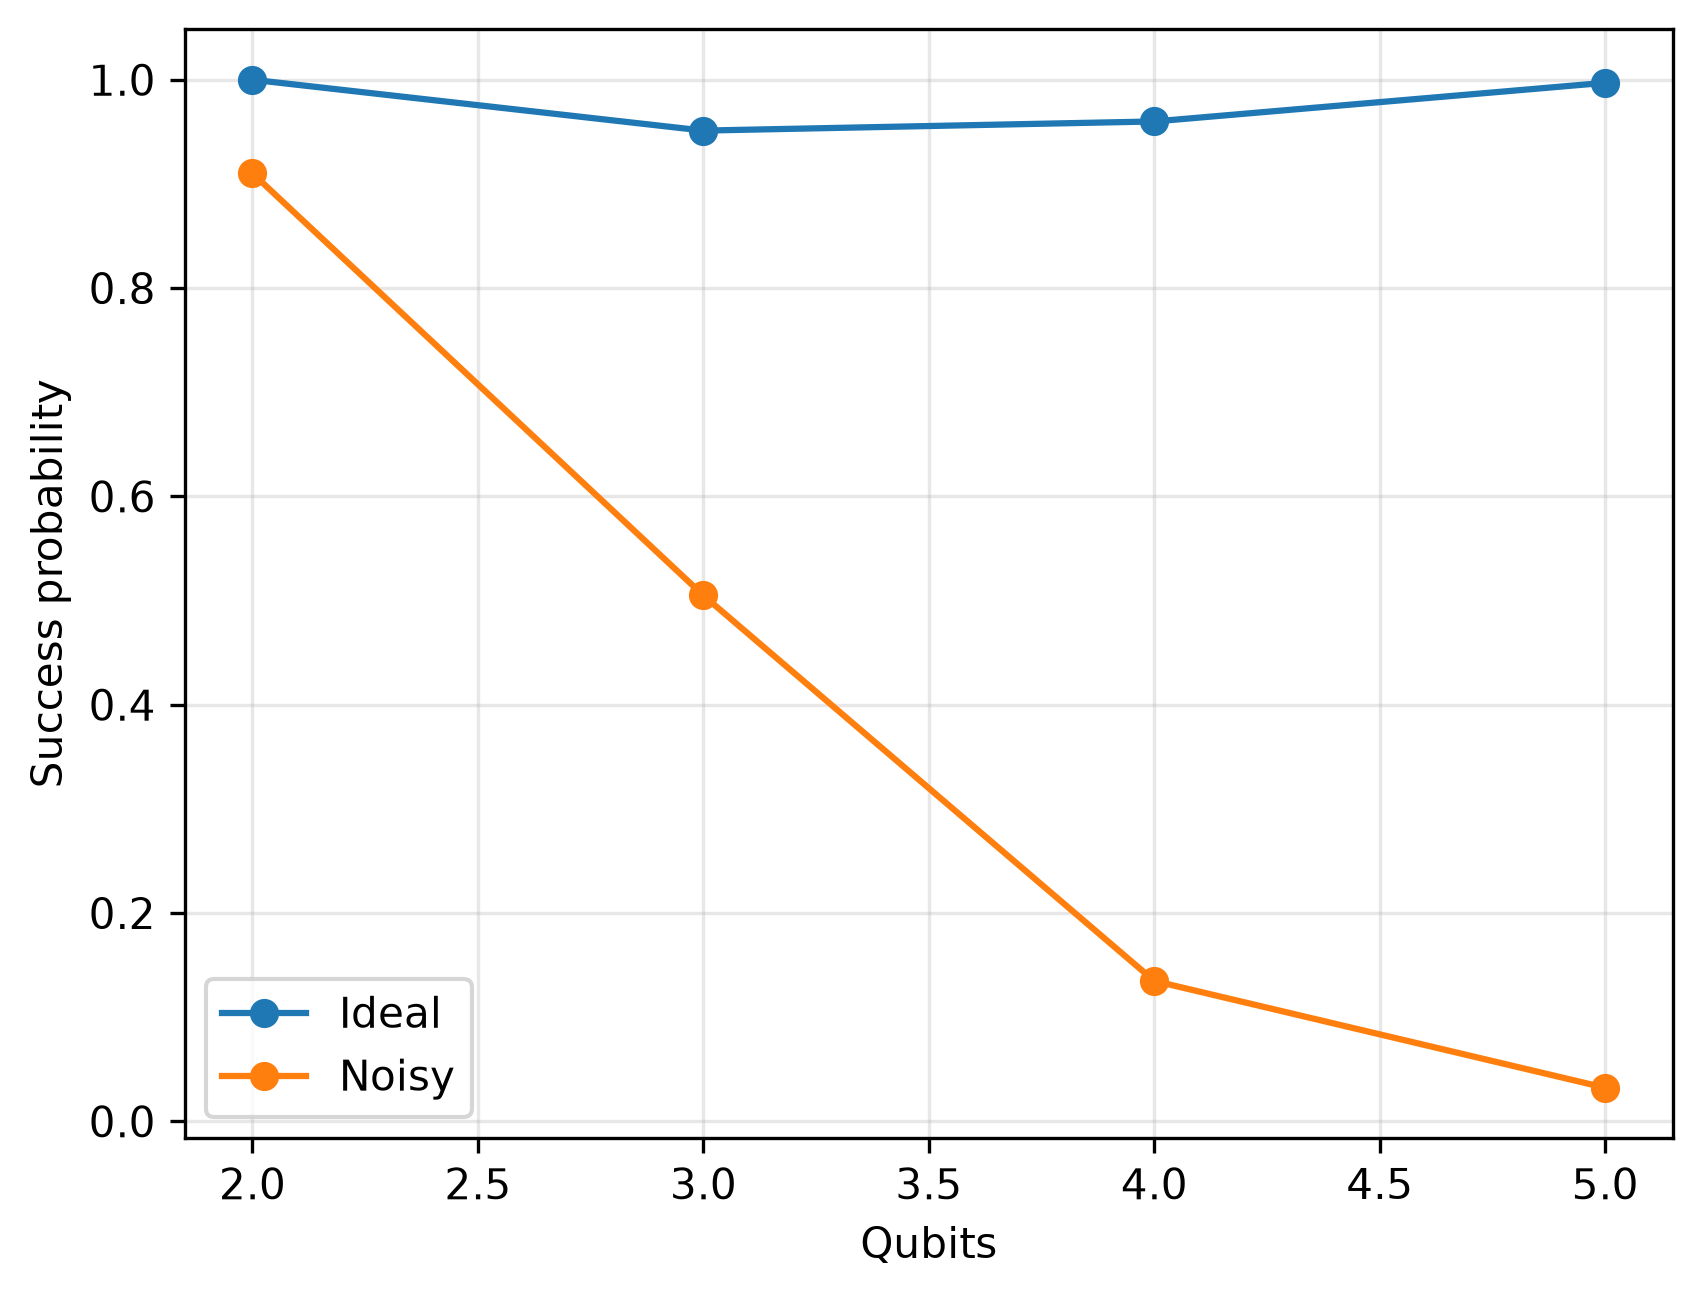

In [11]:
# Noise model
noise_model = NoiseModel()
error_1q = depolarizing_error(0.01, 1)
error_2q = depolarizing_error(0.03, 2)
noise_model.add_all_qubit_quantum_error(error_1q, ["h", "x", "sx"])
noise_model.add_all_qubit_quantum_error(error_2q, ["cx"])

ideal_backend = AerSimulator()
noisy_backend = AerSimulator(noise_model=noise_model)

print("n   N  iters  depth  gates  ideal P  noisy P")
ideal_probs, noisy_probs = [], []
for n in [2, 3, 4, 5]:
    N = 2**n
    target = "1" * n
    k = int(np.floor((np.pi / 4) * np.sqrt(N)))
    qc = grover(n, [target], k)
    compiled = transpile(qc, noisy_backend)

    ideal = ideal_backend.run(
        transpile(qc, ideal_backend), shots=1024
    ).result().get_counts()
    noisy = noisy_backend.run(compiled, shots=1024).result().get_counts()

    p_ideal = ideal.get(target, 0) / 1024
    p_noisy = noisy.get(target, 0) / 1024
    ideal_probs.append(p_ideal)
    noisy_probs.append(p_noisy)
    print(f"{n}  {N:>2}  {k:>5}  {compiled.depth():>5}  {compiled.size():>5}",
          f"  {p_ideal:>7.3f}  {p_noisy:>7.3f}")
    if n <= 3:
        display(plot_histogram([ideal, noisy], legend=["Ideal", "Noisy"],
                               title=f"n = {n}"))

plt.plot([2, 3, 4, 5], ideal_probs, marker="o", label="Ideal")
plt.plot([2, 3, 4, 5], noisy_probs, marker="o", label="Noisy")
plt.xlabel("Qubits")
plt.ylabel("Success probability")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Observation

Ideal success stays near 1 for every size (it dips slightly for $N = 8$ and $N = 32$ because the integer iteration count cannot land exactly on the peak). Under noise the success probability **falls steadily with the number of qubits**: the multi-controlled gates in the oracle and diffusion decompose into many CX gates, so depth and gate count grow quickly and each extra iteration multiplies the chance of an error. For 5 qubits the noisy circuit is already far from the ideal result.

This is why Grover's quadratic speedup is hard to use on NISQ hardware: the advantage needs $\sqrt{N}$ coherent iterations of a deep circuit, but **depolarizing noise washes out the amplified amplitude faster than the iterations build it up**, and without error correction the correct state loses its lead to the uniform background.

## Conclusion

- **Role of the oracle**: it marks the solution by flipping its phase and holds all the problem-specific information.
- **Diffusion operator**: it reflects every amplitude about the mean, converting the phase mark into a larger probability.
- **Initial Hadamards**: they create the uniform superposition in which every candidate is queried at once.
- **Quadratic, not exponential, speedup**: each iteration rotates the state by a fixed small angle, so about $\sqrt{N}$ rotations are needed; this is provably optimal for unstructured search.
- **Marked states and iterations**: more marked states enlarge the rotation angle and reduce the optimal count.
- **Over-iteration**: the rotation overshoots the target and the probability falls again.
- **Noise**: it shrinks the amplified amplitude every iteration and the success probability drops with circuit size.
- **NISQ limits**: deep multi-controlled circuits and the lack of error correction make large searches impractical today.

Grover's algorithm found the target in every noise-free experiment, the optimal iteration count matched the theoretical estimate for N = 4, 8 and 16, the multi-target case showed why the count depends on M, and the noisy runs showed the practical ceiling set by circuit depth.